#load dataset and see pos tags

In [1]:
import random
import math
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

conll_dataset = load_dataset("eriktks/conll2000", revision="refs/convert/parquet")
print(conll_dataset)
print("\nAvailable fields:", conll_dataset["train"].features.keys())

pos_tag_names = conll_dataset["train"].features["pos_tags"].feature.names
print("Number of POS tags:", len(pos_tag_names))
print("POS tag names:", pos_tag_names)

# Inspect one example (we only use 'tokens' and 'pos_tags', never the chunk labels)
first_example = conll_dataset["train"][0]
print("\nExample tokens  :", first_example["tokens"])

example_tag_names = []
for tag_id in first_example["pos_tags"]:
    example_tag_names.append(pos_tag_names[tag_id])
print("Example POS tags:", example_tag_names)

c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 8937
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 2013
    })
})

Available fields: dict_keys(['id', 'tokens', 'pos_tags', 'chunk_tags'])
Number of POS tags: 44
POS tag names: ["''", '#', '$', '(', ')', ',', '.', ':', '``', 'CC', 'CD', 'DT', 'EX', 'FW', 'IN', 'JJ', 'JJR', 'JJS', 'MD', 'NN', 'NNP', 'NNPS', 'NNS', 'PDT', 'POS', 'PRP', 'PRP$', 'RB', 'RBR', 'RBS', 'RP', 'SYM', 'TO', 'UH', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ', 'WDT', 'WP', 'WP$', 'WRB']

Example tokens  : ['Confidence', 'in', 'the', 'pound', 'is', 'widely', 'expected', 'to', 'take', 'another', 'sharp', 'dive', 'if', 'trade', 'figures', 'for', 'September', ',', 'due', 'for', 'release', 'tomorrow', ',', 'fail', 'to', 'show', 'a', 'substantial', 'improvement', 'from', 'July', 'and', 'August', "'s", 'near-record', 'deficits', '.']
Example POS tags: ['

In [2]:
# Convert the Hugging Face rows into plain Python lists.
# Each sentence is stored as (list_of_words, list_of_tag_names).
# Only 'tokens' and 'pos_tags' are read. 'chunk_tags' is never used.

def convert_split_to_sentences(hf_split, tag_names):
    sentence_list = []
    for row in hf_split:
        word_list = row["tokens"]

        tag_name_list = []
        for tag_id in row["pos_tags"]:
            tag_name_list.append(tag_names[tag_id])

        sentence_list.append((word_list, tag_name_list))
    return sentence_list


all_train_sentences = convert_split_to_sentences(conll_dataset["train"], pos_tag_names)
test_sentences = convert_split_to_sentences(conll_dataset["test"], pos_tag_names)

# Reproducible split: shuffle sentence indices with a fixed seed, then cut
VALIDATION_FRACTION = 0.10

split_random_generator = random.Random(RANDOM_SEED)
shuffled_indices = list(range(len(all_train_sentences)))
split_random_generator.shuffle(shuffled_indices)

number_of_validation_sentences = int(len(all_train_sentences) * VALIDATION_FRACTION)

validation_indices = shuffled_indices[:number_of_validation_sentences]
train_indices = shuffled_indices[number_of_validation_sentences:]

train_sentences = []
for index in train_indices:
    train_sentences.append(all_train_sentences[index])

validation_sentences = []
for index in validation_indices:
    validation_sentences.append(all_train_sentences[index])

# Sanity checks
print("Original training sentences :", len(all_train_sentences))
print("New training sentences      :", len(train_sentences))
print("Validation sentences        :", len(validation_sentences))
print("Test sentences (untouched)  :", len(test_sentences))

overlap_indices = set(train_indices) & set(validation_indices)
print("Train/validation overlap    :", len(overlap_indices), "(must be 0)")

# Every sentence must have exactly one tag per word
all_lengths_match = True
for word_list, tag_name_list in train_sentences + validation_sentences + test_sentences:
    if len(word_list) != len(tag_name_list):
        all_lengths_match = False
print("Words and tags aligned      :", all_lengths_match)

# Token counts per split
def count_tokens(sentence_list):
    total_tokens = 0
    for word_list, tag_name_list in sentence_list:
        total_tokens = total_tokens + len(word_list)
    return total_tokens

print("\nTokens in train     :", count_tokens(train_sentences))
print("Tokens in validation:", count_tokens(validation_sentences))
print("Tokens in test      :", count_tokens(test_sentences))

# Look at one training sentence, word next to tag
print("\nFirst training sentence after the split:")
print("{:<5} {:<15} {}".format("Pos.", "Word", "POS tag"))
print("-" * 30)
first_words, first_tags = train_sentences[0]
for position in range(len(first_words)):
    print("{:<5} {:<15} {}".format(position, first_words[position], first_tags[position]))

Original training sentences : 8937
New training sentences      : 8044
Validation sentences        : 893
Test sentences (untouched)  : 2013
Train/validation overlap    : 0 (must be 0)
Words and tags aligned      : True

Tokens in train     : 190971
Tokens in validation: 20756
Tokens in test      : 47377

First training sentence after the split:
Pos.  Word            POS tag
------------------------------
0     Carriers        NNP
1     boosted         VBD
2     rates           NNS
3     more            JJR
4     than            IN
5     10              CD
6     %               NN
7     in              IN
8     the             DT
9     North           NNP
10    Atlantic        NNP
11    between         IN
12    the             DT
13    U.S.            NNP
14    and             CC
15    Europe          NNP
16    last            JJ
17    September       NNP
18    ,               ,
19    hoping          VBG
20    to              TO
21    partly          RB
22    restore         VB
23    rat

In [3]:


def normalize_token(raw_token):
    lowercase_token = raw_token.lower()


    token_without_separators = lowercase_token
    for separator_character in [",", ".", "-", "/", ":"]:
        token_without_separators = token_without_separators.replace(separator_character, "")

    if token_without_separators.isdigit():
        return "<NUM>"
    else:
        return lowercase_token


def normalize_word_list(word_list):
    normalized_words = []
    for raw_token in word_list:
        normalized_words.append(normalize_token(raw_token))
    return normalized_words


# Show the effect on a few examples
example_raw_tokens = ["The", "Confidence", "1,000", "3.5", "1990", ",", ".", "near-record", "10-year"]
print("Raw token       -> normalized token")
for raw_token in example_raw_tokens:
    print("{:<15} -> {}".format(raw_token, normalize_token(raw_token)))



train_word_lists = []
for word_list, tag_name_list in train_sentences:
    train_word_lists.append(normalize_word_list(word_list))

validation_word_lists = []
for word_list, tag_name_list in validation_sentences:
    validation_word_lists.append(normalize_word_list(word_list))

test_word_lists = []
for word_list, tag_name_list in test_sentences:
    test_word_lists.append(normalize_word_list(word_list))



training_word_counts = {}
for word_list in train_word_lists:
    for word in word_list:
        if word in training_word_counts:
            training_word_counts[word] = training_word_counts[word] + 1
        else:
            training_word_counts[word] = 1

total_training_tokens = 0
for word in training_word_counts:
    total_training_tokens = total_training_tokens + training_word_counts[word]

print("\nTotal training tokens          :", total_training_tokens)
print("Distinct word types in training:", len(training_word_counts))




def get_sort_key(word_count_pair):
    word = word_count_pair[0]
    count = word_count_pair[1]
    return (-count, word)


sorted_word_count_pairs = sorted(training_word_counts.items(), key=get_sort_key)

print("\nTop 15 most frequent words:")
for word, count in sorted_word_count_pairs[:15]:
    print("{:<10} {}".format(word, count))




MIN_WORD_COUNT = 2
UNKNOWN_TOKEN = "<UNK>"

index_to_word = [UNKNOWN_TOKEN]

for word, count in sorted_word_count_pairs:
    if count >= MIN_WORD_COUNT:
        index_to_word.append(word)

word_to_index = {}
for index in range(len(index_to_word)):
    word_to_index[index_to_word[index]] = index

vocabulary_size = len(index_to_word)
print("\nMIN_WORD_COUNT                    :", MIN_WORD_COUNT)
print("Vocabulary size (including <UNK>) :", vocabulary_size)




def compute_coverage(word_lists, word_to_index_mapping):
    known_token_count = 0
    unknown_token_count = 0
    for word_list in word_lists:
        for word in word_list:
            if word in word_to_index_mapping:
                known_token_count = known_token_count + 1
            else:
                unknown_token_count = unknown_token_count + 1

    total_count = known_token_count + unknown_token_count
    unknown_percentage = 100.0 * unknown_token_count / total_count
    return known_token_count, unknown_token_count, unknown_percentage


print("\nVocabulary coverage:")
print("{:<12} {:>10} {:>10} {:>12}".format("Split", "Known", "Unknown", "Unknown %"))
print("-" * 46)

split_names = ["train", "validation", "test"]
split_word_lists_in_order = [train_word_lists, validation_word_lists, test_word_lists]

for split_position in range(len(split_names)):
    known_count, unknown_count, unknown_percentage = compute_coverage(
        split_word_lists_in_order[split_position], word_to_index
    )
    print("{:<12} {:>10} {:>10} {:>11.2f}%".format(
        split_names[split_position], known_count, unknown_count, unknown_percentage
    ))

Raw token       -> normalized token
The             -> the
Confidence      -> confidence
1,000           -> <NUM>
3.5             -> <NUM>
1990            -> <NUM>
,               -> ,
.               -> .
near-record     -> near-record
10-year         -> 10-year

Total training tokens          : 190971
Distinct word types in training: 14799

Top 15 most frequent words:
the        9726
,          9703
.          7859
<NUM>      5074
of         4714
to         4566
a          4011
in         3426
and        3328
for        1785
's         1726
that       1720
$          1568
``         1349
''         1315

MIN_WORD_COUNT                    : 2
Vocabulary size (including <UNK>) : 7891

Vocabulary coverage:
Split             Known    Unknown    Unknown %
----------------------------------------------
train            184062       6909        3.62%
validation        19522       1234        5.95%
test              43365       4012        8.47%


In [4]:


def convert_to_index_list(word_list, word_to_index_mapping):
    index_list = []
    for word in word_list:
        if word in word_to_index_mapping:
            index_list.append(word_to_index_mapping[word])
        else:
            index_list.append(word_to_index_mapping[UNKNOWN_TOKEN])
    return index_list


def convert_all_sentences_to_indices(word_lists, word_to_index_mapping):
    all_index_lists = []
    for word_list in word_lists:
        all_index_lists.append(convert_to_index_list(word_list, word_to_index_mapping))
    return all_index_lists


train_index_lists = convert_all_sentences_to_indices(train_word_lists, word_to_index)
validation_index_lists = convert_all_sentences_to_indices(validation_word_lists, word_to_index)
test_index_lists = convert_all_sentences_to_indices(test_word_lists, word_to_index)

unknown_index = word_to_index[UNKNOWN_TOKEN]

print("First training sentence as words  :", train_word_lists[0][:10])
print("First training sentence as indices:", train_index_lists[0][:10])




CONTEXT_WINDOW_SIZE = 2

def build_cooccurrence_counts(index_lists, window_size, unknown_word_index):

    cooccurrence_counts = {}

    for sentence_indices in index_lists:
        sentence_length = len(sentence_indices)

        for center_position in range(sentence_length):
            center_index = sentence_indices[center_position]

            if center_index == unknown_word_index:
                continue

            window_start = max(0, center_position - window_size)
            window_end = min(sentence_length - 1, center_position + window_size)

            for context_position in range(window_start, window_end + 1):
                if context_position == center_position:
                    continue

                context_index = sentence_indices[context_position]

                if context_index == unknown_word_index:
                    continue

                if center_index not in cooccurrence_counts:
                    cooccurrence_counts[center_index] = {}

                context_counts_for_center = cooccurrence_counts[center_index]

                if context_index in context_counts_for_center:
                    context_counts_for_center[context_index] = context_counts_for_center[context_index] + 1
                else:
                    context_counts_for_center[context_index] = 1

    return cooccurrence_counts


cooccurrence_counts = build_cooccurrence_counts(train_index_lists, CONTEXT_WINDOW_SIZE, unknown_index)



number_of_rows_with_data = len(cooccurrence_counts)
number_of_nonzero_cells = 0
total_pair_count = 0

for center_index in cooccurrence_counts:
    context_counts_for_center = cooccurrence_counts[center_index]
    number_of_nonzero_cells = number_of_nonzero_cells + len(context_counts_for_center)
    for context_index in context_counts_for_center:
        total_pair_count = total_pair_count + context_counts_for_center[context_index]

number_of_cells_in_full_matrix = vocabulary_size * vocabulary_size
percentage_of_cells_filled = 100.0 * number_of_nonzero_cells / number_of_cells_in_full_matrix

print("\nContext window size (each side)   :", CONTEXT_WINDOW_SIZE)
print("Vocabulary size                   :", vocabulary_size)
print("Rows that have data               :", number_of_rows_with_data)
print("Total word-context pairs counted  :", total_pair_count)
print("Non-zero cells (stored)           :", number_of_nonzero_cells)
print("Cells in a full dense matrix      :", number_of_cells_in_full_matrix)
print("Percentage of cells that are used : {:.2f}%".format(percentage_of_cells_filled))




def show_top_raw_contexts(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    query_index = word_to_index[query_word]
    context_counts_for_query = cooccurrence_counts[query_index]

    context_count_pairs = []
    for context_index in context_counts_for_query:
        context_count_pairs.append((index_to_word[context_index], context_counts_for_query[context_index]))

    def get_count_then_word_key(pair):
        return (-pair[1], pair[0])

    context_count_pairs.sort(key=get_count_then_word_key)

    print("\nTop raw contexts for '{}':".format(query_word))
    for context_word, count in context_count_pairs[:how_many]:
        print("   {:<12} {}".format(context_word, count))


show_top_raw_contexts("market", 8)
show_top_raw_contexts("said", 8)
show_top_raw_contexts("company", 8)

First training sentence as words  : ['carriers', 'boosted', 'rates', 'more', 'than', '<NUM>', '%', 'in', 'the', 'north']
First training sentence as indices: [1550, 1950, 159, 51, 61, 4, 17, 8, 1, 825]

Context window size (each side)   : 2
Vocabulary size                   : 7891
Rows that have data               : 7890
Total word-context pairs counted  : 664594
Non-zero cells (stored)           : 274581
Cells in a full dense matrix      : 62267881
Percentage of cells that are used : 0.44%

Top raw contexts for 'market':
   the          200
   ,            85
   .            58
   stock        47
   a            32
   's           31
   of           21
   to           21

Top raw contexts for 'said':
   ,            448
   the          240
   .            191
   it           165
   he           135
   ''           128
   mr.          101
   company      69

Top raw contexts for 'company':
   the          329
   ,            119
   's           114
   said         69
   a            67


In [5]:
CONTEXT_SMOOTHING_ALPHA = 0.75    # hyperparameter: 1.0 means no smoothing

total_pair_count = 0
row_totals = {}       # how many pairs each word takes part in as the center word
column_totals = {}    # how many pairs each word takes part in as the context word

for center_index in cooccurrence_counts:
    context_counts_for_center = cooccurrence_counts[center_index]
    row_totals[center_index] = 0

    for context_index in context_counts_for_center:
        pair_count = context_counts_for_center[context_index]

        total_pair_count = total_pair_count + pair_count
        row_totals[center_index] = row_totals[center_index] + pair_count

        if context_index in column_totals:
            column_totals[context_index] = column_totals[context_index] + pair_count
        else:
            column_totals[context_index] = pair_count

# Smoothed context probabilities: P_alpha(c) = count(c)^alpha / sum of count(c')^alpha
smoothed_column_total_sum = 0.0
for context_index in column_totals:
    smoothed_column_total_sum = smoothed_column_total_sum + column_totals[context_index] ** CONTEXT_SMOOTHING_ALPHA

smoothed_context_probability = {}
for context_index in column_totals:
    smoothed_count = column_totals[context_index] ** CONTEXT_SMOOTHING_ALPHA
    smoothed_context_probability[context_index] = smoothed_count / smoothed_column_total_sum

print("Total word-context pairs:", total_pair_count)




ppmi_vectors = {}              # ppmi_vectors[word_index][context_index] = PPMI value
number_of_positive_cells = 0
number_of_negative_cells = 0

for center_index in cooccurrence_counts:
    context_counts_for_center = cooccurrence_counts[center_index]
    probability_of_center = row_totals[center_index] / total_pair_count

    ppmi_row = {}

    for context_index in context_counts_for_center:
        pair_count = context_counts_for_center[context_index]

        probability_of_pair = pair_count / total_pair_count
        probability_of_context = smoothed_context_probability[context_index]

        pmi_value = math.log2(probability_of_pair / (probability_of_center * probability_of_context))

        if pmi_value > 0:
            ppmi_row[context_index] = pmi_value
            number_of_positive_cells = number_of_positive_cells + 1
        else:
            number_of_negative_cells = number_of_negative_cells + 1

    ppmi_vectors[center_index] = ppmi_row

print("\nCells with positive PMI (kept)      :", number_of_positive_cells)
print("Cells with PMI <= 0 (dropped, = 0)  :", number_of_negative_cells)



def show_top_ppmi_contexts(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    query_index = word_to_index[query_word]
    ppmi_row = ppmi_vectors[query_index]
    raw_count_row = cooccurrence_counts[query_index]

    context_value_triples = []
    for context_index in ppmi_row:
        context_value_triples.append((index_to_word[context_index],
                                      ppmi_row[context_index],
                                      raw_count_row[context_index]))

    def get_ppmi_then_word_key(triple):
        return (-triple[1], triple[0])

    context_value_triples.sort(key=get_ppmi_then_word_key)

    print("\nTop PPMI contexts for '{}':".format(query_word))
    print("   {:<14} {:>8} {:>10}".format("Context", "PPMI", "Raw count"))
    for context_word, ppmi_value, raw_count in context_value_triples[:how_many]:
        print("   {:<14} {:>8.2f} {:>10}".format(context_word, ppmi_value, raw_count))


show_top_ppmi_contexts("market", 8)
show_top_ppmi_contexts("said", 8)
show_top_ppmi_contexts("company", 8)

Total word-context pairs: 664594

Cells with positive PMI (kept)      : 251238
Cells with PMI <= 0 (dropped, = 0)  : 23343

Top PPMI contexts for 'market':
   Context            PPMI  Raw count
   barometer          5.56          2
   strategist         5.52          5
   bull               5.46          3
   gyrations          5.37          4
   participants       5.32          4
   commentary         5.15          3
   new-issue          5.12          2
   durable            4.87          1

Top PPMI contexts for 'said':
   Context            PPMI  Raw count
   hoechst            4.73          2
   knowledgeable      4.73          2
   spokesman          4.46         39
   dillow             4.33          3
   sri                4.30          4
   eric               4.29          2
   fitzwater          4.25          6
   crandall           4.13          2

Top PPMI contexts for 'company':
   Context            PPMI  Raw count
   calif.-based       5.33          2
   holding         

In [6]:


def compute_vector_norm(sparse_vector):
    sum_of_squares = 0.0
    for context_index in sparse_vector:
        value = sparse_vector[context_index]
        sum_of_squares = sum_of_squares + value * value
    return math.sqrt(sum_of_squares)


def compute_all_norms(vector_table):
    norm_table = {}
    for word_index in vector_table:
        norm_table[word_index] = compute_vector_norm(vector_table[word_index])
    return norm_table


def compute_sparse_dot_product(vector_a, vector_b):

    if len(vector_a) <= len(vector_b):
        smaller_vector = vector_a
        larger_vector = vector_b
    else:
        smaller_vector = vector_b
        larger_vector = vector_a

    dot_product = 0.0
    for context_index in smaller_vector:
        if context_index in larger_vector:
            dot_product = dot_product + smaller_vector[context_index] * larger_vector[context_index]
    return dot_product


def compute_cosine_similarity(vector_a, norm_a, vector_b, norm_b):
    if norm_a == 0.0 or norm_b == 0.0:
        return 0.0
    dot_product = compute_sparse_dot_product(vector_a, vector_b)
    return dot_product / (norm_a * norm_b)


ppmi_norms = compute_all_norms(ppmi_vectors)
raw_count_norms = compute_all_norms(cooccurrence_counts)




def find_nearest_neighbors(query_word, vector_table, norm_table, how_many):
    query_index = word_to_index[query_word]
    query_vector = vector_table[query_index]
    query_norm = norm_table[query_index]

    similarity_pairs = []
    for candidate_index in vector_table:
        if candidate_index == query_index:
            continue

        similarity = compute_cosine_similarity(
            query_vector, query_norm,
            vector_table[candidate_index], norm_table[candidate_index]
        )
        similarity_pairs.append((candidate_index, similarity))

    def get_similarity_then_index_key(pair):
        return (-pair[1], pair[0])

    similarity_pairs.sort(key=get_similarity_then_index_key)
    return similarity_pairs[:how_many]


def print_neighbors_side_by_side(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    ppmi_neighbors = find_nearest_neighbors(query_word, ppmi_vectors, ppmi_norms, how_many)
    raw_neighbors = find_nearest_neighbors(query_word, cooccurrence_counts, raw_count_norms, how_many)

    print("\nQuery word: '{}'  (training frequency: {})".format(
        query_word, training_word_counts[query_word]))
    print("   {:<26} | {:<26}".format("PPMI neighbors (cosine)", "Raw-count neighbors (cosine)"))
    print("   " + "-" * 55)

    for rank in range(how_many):
        ppmi_index, ppmi_similarity = ppmi_neighbors[rank]
        raw_index, raw_similarity = raw_neighbors[rank]

        ppmi_text = "{} ({:.3f})".format(index_to_word[ppmi_index], ppmi_similarity)
        raw_text = "{} ({:.3f})".format(index_to_word[raw_index], raw_similarity)

        print("   {:<26} | {:<26}".format(ppmi_text, raw_text))




query_words_for_comparison = ["market", "company", "president", "price", "bank", "said", "january", "big"]

for query_word in query_words_for_comparison:
    print_neighbors_side_by_side(query_word, 8)


Query word: 'market'  (training frequency: 349)
   PPMI neighbors (cosine)    | Raw-count neighbors (cosine)
   -------------------------------------------------------
   stock (0.149)              | quake (0.932)             
   arena (0.140)              | company (0.927)           
   plunge (0.139)             | government (0.925)        
   participants (0.128)       | economy (0.921)           
   stock-market (0.117)       | industry (0.917)          
   markets (0.117)            | on (0.912)                
   friday (0.117)             | dollar (0.902)            
   calendar (0.116)           | same (0.900)              

Query word: 'company'  (training frequency: 456)
   PPMI neighbors (cosine)    | Raw-count neighbors (cosine)
   -------------------------------------------------------
   it (0.131)                 | government (0.938)        
   ex-im (0.124)              | quake (0.927)             
   loral (0.119)              | market (0.927)            
   sterling 

In [7]:


number_of_documents = len(train_index_lists)

# term_document_counts[word_index][document_id] = count(t, d)
term_document_counts = {}

for document_id in range(number_of_documents):
    sentence_indices = train_index_lists[document_id]

    for word_index in sentence_indices:
        if word_index == unknown_index:
            continue

        if word_index not in term_document_counts:
            term_document_counts[word_index] = {}

        counts_for_word = term_document_counts[word_index]

        if document_id in counts_for_word:
            counts_for_word[document_id] = counts_for_word[document_id] + 1
        else:
            counts_for_word[document_id] = 1

print("Number of documents (training sentences):", number_of_documents)
print("Words with document counts              :", len(term_document_counts))




def compute_term_frequency(raw_count):
    # tf = 1 + log10(count) if count > 0, otherwise 0
    if raw_count > 0:
        return 1.0 + math.log10(raw_count)
    else:
        return 0.0


def compute_inverse_document_frequency(total_documents, document_frequency):
    # idf = log10(N / df)
    return math.log10(total_documents / document_frequency)


document_frequency = {}
inverse_document_frequency = {}

for word_index in term_document_counts:
    document_frequency[word_index] = len(term_document_counts[word_index])
    inverse_document_frequency[word_index] = compute_inverse_document_frequency(
        number_of_documents, document_frequency[word_index]
    )

# Check our function against the slide: N = 37, df = 1 should give about 1.57
print("\nCheck against the slide (N=37, df=1):", round(compute_inverse_document_frequency(37, 1), 3))
print("Check against the slide (N=37, df=4):", round(compute_inverse_document_frequency(37, 4), 3))




tfidf_vectors = {}

for word_index in term_document_counts:
    tfidf_row = {}
    counts_for_word = term_document_counts[word_index]

    for document_id in counts_for_word:
        term_frequency = compute_term_frequency(counts_for_word[document_id])
        tfidf_row[document_id] = term_frequency * inverse_document_frequency[word_index]

    tfidf_vectors[word_index] = tfidf_row

tfidf_norms = compute_all_norms(tfidf_vectors)




number_of_nonzero_tfidf_cells = 0
for word_index in tfidf_vectors:
    number_of_nonzero_tfidf_cells = number_of_nonzero_tfidf_cells + len(tfidf_vectors[word_index])

number_of_cells_in_full_tfidf_matrix = len(tfidf_vectors) * number_of_documents
tfidf_percentage_filled = 100.0 * number_of_nonzero_tfidf_cells / number_of_cells_in_full_tfidf_matrix

print("\nWords (rows)                      :", len(tfidf_vectors))
print("Documents (columns)               :", number_of_documents)
print("Non-zero cells (stored)           :", number_of_nonzero_tfidf_cells)
print("Cells in a full dense matrix      :", number_of_cells_in_full_tfidf_matrix)
print("Percentage of cells that are used : {:.3f}%".format(tfidf_percentage_filled))


def get_document_frequency_key(word_index):
    return (-document_frequency[word_index], index_to_word[word_index])

words_sorted_by_document_frequency = sorted(document_frequency.keys(), key=get_document_frequency_key)

print("\nIn the most sentences (lowest IDF):")
print("   {:<10} {:>6} {:>8}".format("Word", "df", "idf"))
for word_index in words_sorted_by_document_frequency[:8]:
    print("   {:<10} {:>6} {:>8.3f}".format(
        index_to_word[word_index], document_frequency[word_index], inverse_document_frequency[word_index]))

print("\nIn the fewest sentences (highest IDF):")
print("   {:<14} {:>6} {:>8}".format("Word", "df", "idf"))
for word_index in words_sorted_by_document_frequency[-5:]:
    print("   {:<14} {:>6} {:>8.3f}".format(
        index_to_word[word_index], document_frequency[word_index], inverse_document_frequency[word_index]))




def print_tfidf_and_ppmi_neighbors(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    tfidf_neighbors = find_nearest_neighbors(query_word, tfidf_vectors, tfidf_norms, how_many)
    ppmi_neighbors = find_nearest_neighbors(query_word, ppmi_vectors, ppmi_norms, how_many)

    print("\nQuery word: '{}'  (document frequency: {})".format(
        query_word, document_frequency[word_to_index[query_word]]))
    print("   {:<26} | {:<26}".format("TF-IDF neighbors (cosine)", "PPMI neighbors (cosine)"))
    print("   " + "-" * 55)

    for rank in range(how_many):
        tfidf_index, tfidf_similarity = tfidf_neighbors[rank]
        ppmi_index, ppmi_similarity = ppmi_neighbors[rank]

        tfidf_text = "{} ({:.3f})".format(index_to_word[tfidf_index], tfidf_similarity)
        ppmi_text = "{} ({:.3f})".format(index_to_word[ppmi_index], ppmi_similarity)

        print("   {:<26} | {:<26}".format(tfidf_text, ppmi_text))


for query_word in query_words_for_comparison:
    print_tfidf_and_ppmi_neighbors(query_word, 8)

Number of documents (training sentences): 8044
Words with document counts              : 7890

Check against the slide (N=37, df=1): 1.568
Check against the slide (N=37, df=4): 0.966

Words (rows)                      : 7890
Documents (columns)               : 8044
Non-zero cells (stored)           : 161120
Cells in a full dense matrix      : 63467160
Percentage of cells that are used : 0.254%

In the most sentences (lowest IDF):
   Word           df      idf
   .            7821    0.012
   the          5373    0.175
   ,            5095    0.198
   to           3418    0.372
   of           3417    0.372
   a            3011    0.427
   in           2738    0.468
   and          2722    0.471

In the fewest sentences (highest IDF):
   Word               df      idf
   vaezi               1    3.905
   vail                1    3.905
   watt                1    3.905
   weston              1    3.905
   yusen               1    3.905

Query word: 'market'  (document frequency: 324)
   

In [8]:

WORD2VEC_WINDOW_SIZE = 2            # words on each side of the center word
NUMBER_OF_NEGATIVE_SAMPLES = 5      # negative words drawn per positive pair
NOISE_DISTRIBUTION_POWER = 0.75     # frequency ^ 0.75 for the noise distribution




def build_skipgram_pairs(index_lists, window_size, unknown_word_index):
    center_index_list = []
    context_index_list = []

    for sentence_indices in index_lists:
        sentence_length = len(sentence_indices)

        for center_position in range(sentence_length):
            center_index = sentence_indices[center_position]

            if center_index == unknown_word_index:
                continue

            window_start = max(0, center_position - window_size)
            window_end = min(sentence_length - 1, center_position + window_size)

            for context_position in range(window_start, window_end + 1):
                if context_position == center_position:
                    continue

                context_index = sentence_indices[context_position]

                if context_index == unknown_word_index:
                    continue

                center_index_list.append(center_index)
                context_index_list.append(context_index)

    center_indices_array = np.array(center_index_list, dtype=np.int64)
    context_indices_array = np.array(context_index_list, dtype=np.int64)
    return center_indices_array, context_indices_array


training_center_indices, training_context_indices = build_skipgram_pairs(
    train_index_lists, WORD2VEC_WINDOW_SIZE, unknown_index
)

number_of_training_pairs = len(training_center_indices)

print("Window size (each side)        :", WORD2VEC_WINDOW_SIZE)
print("Number of positive pairs       :", number_of_training_pairs)
print("Shape of center index array    :", training_center_indices.shape)
print("Shape of context index array   :", training_context_indices.shape)

print("\nFirst 8 positive pairs (center word -> context word):")
for pair_position in range(8):
    center_word = index_to_word[training_center_indices[pair_position]]
    context_word = index_to_word[training_context_indices[pair_position]]
    print("   {:<12} -> {}".format(center_word, context_word))




# Frequency of every vocabulary word (index 0 is <UNK>, which must never be sampled)
vocabulary_word_frequencies = np.zeros(vocabulary_size, dtype=np.float64)

for word_index in range(vocabulary_size):
    if word_index == unknown_index:
        vocabulary_word_frequencies[word_index] = 0.0
    else:
        word_text = index_to_word[word_index]
        vocabulary_word_frequencies[word_index] = training_word_counts[word_text]

smoothed_word_frequencies = vocabulary_word_frequencies ** NOISE_DISTRIBUTION_POWER
noise_distribution = smoothed_word_frequencies / np.sum(smoothed_word_frequencies)

print("\nNoise distribution sums to        :", np.sum(noise_distribution))
print("Probability given to <UNK>        :", noise_distribution[unknown_index])

# Compare plain frequency with the smoothed noise probability for a few words
raw_frequency_distribution = vocabulary_word_frequencies / np.sum(vocabulary_word_frequencies)

print("\nRaw probability vs noise probability:")
print("   {:<12} {:>14} {:>16}".format("Word", "Raw prob.", "Noise prob."))
for demo_word in ["the", "market", "company", "january"]:
    if demo_word in word_to_index:
        demo_index = word_to_index[demo_word]
        print("   {:<12} {:>14.6f} {:>16.6f}".format(
            demo_word, raw_frequency_distribution[demo_index], noise_distribution[demo_index]))




word2vec_random_generator = np.random.RandomState(RANDOM_SEED)

def draw_negative_samples(number_of_pairs, negatives_per_pair, true_context_indices):
    # Draw random words from the noise distribution, shape (number_of_pairs, negatives_per_pair)
    negative_sample_indices = word2vec_random_generator.choice(
        vocabulary_size,
        size=(number_of_pairs, negatives_per_pair),
        p=noise_distribution
    )

    # A negative sample must not be the true context word of its own pair.
    # If it is, draw again for that position until it is different.
    for pair_position in range(number_of_pairs):
        for negative_position in range(negatives_per_pair):
            while negative_sample_indices[pair_position, negative_position] == true_context_indices[pair_position]:
                negative_sample_indices[pair_position, negative_position] = word2vec_random_generator.choice(
                    vocabulary_size, p=noise_distribution
                )

    return negative_sample_indices




test_batch_size = 4
test_centers = training_center_indices[:test_batch_size]
test_contexts = training_context_indices[:test_batch_size]
test_negatives = draw_negative_samples(test_batch_size, NUMBER_OF_NEGATIVE_SAMPLES, test_contexts)

print("\nSampler test (1 positive pair and its negatives):")
for pair_position in range(test_batch_size):
    negative_words = []
    for negative_index in test_negatives[pair_position]:
        negative_words.append(index_to_word[negative_index])

    print("   center={:<10} true context={:<10} negatives={}".format(
        index_to_word[test_centers[pair_position]],
        index_to_word[test_contexts[pair_position]],
        negative_words
    ))

# Check: over many draws, the sampled frequencies should follow the noise distribution
number_of_check_draws = 200000
check_draws = word2vec_random_generator.choice(vocabulary_size, size=number_of_check_draws, p=noise_distribution)

print("\nCheck: expected vs observed sampling rate")
print("   {:<12} {:>12} {:>12}".format("Word", "Expected", "Observed"))
for demo_word in ["the", "market", "company"]:
    if demo_word in word_to_index:
        demo_index = word_to_index[demo_word]
        observed_rate = np.sum(check_draws == demo_index) / number_of_check_draws
        print("   {:<12} {:>12.6f} {:>12.6f}".format(demo_word, noise_distribution[demo_index], observed_rate))

Window size (each side)        : 2
Number of positive pairs       : 664594
Shape of center index array    : (664594,)
Shape of context index array   : (664594,)

First 8 positive pairs (center word -> context word):
   carriers     -> boosted
   carriers     -> rates
   boosted      -> carriers
   boosted      -> rates
   boosted      -> more
   rates        -> carriers
   rates        -> boosted
   rates        -> more

Noise distribution sums to        : 1.0000000000000002
Probability given to <UNK>        : 0.0

Raw probability vs noise probability:
   Word              Raw prob.      Noise prob.
   the                0.052841         0.017643
   market             0.001896         0.001455
   company            0.002477         0.001778
   january            0.000071         0.000123

Sampler test (1 positive pair and its negatives):
   center=carriers   true context=boosted    negatives=['?', 'dreaded', 'eliminate', 'meet', 'from']
   center=carriers   true context=rates      nega

In [9]:
import time



EMBEDDING_DIMENSION = 50      # size of each dense vector
LEARNING_RATE = 0.025         # SGD step size
NUMBER_OF_EPOCHS = 5          # passes over all training pairs
BATCH_SIZE = 128              # pairs processed together before one update




def sigmoid(scores):
    # clip so np.exp never overflows
    clipped_scores = np.clip(scores, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-clipped_scores))


def log_sigmoid(scores):
    # log(sigmoid(x)) = -log(1 + exp(-x)), computed in a numerically stable way
    return -np.logaddexp(0.0, -scores)




def initialize_embeddings(size_of_vocabulary, dimension, random_generator):
    initial_bound = 0.5 / dimension
    center_matrix = random_generator.uniform(-initial_bound, initial_bound, size=(size_of_vocabulary, dimension))
    context_matrix = random_generator.uniform(-initial_bound, initial_bound, size=(size_of_vocabulary, dimension))
    return center_matrix, context_matrix



# center_indices:   shape (B,)
# context_indices:  shape (B,)
# negative_indices: shape (B, K)

def compute_forward_pass(center_matrix, context_matrix, center_indices, context_indices, negative_indices):
    center_vectors = center_matrix[center_indices]            # (B, D)
    positive_vectors = context_matrix[context_indices]        # (B, D)
    negative_vectors = context_matrix[negative_indices]       # (B, K, D)

    positive_scores = np.sum(center_vectors * positive_vectors, axis=1)                         # (B,)
    negative_scores = np.sum(center_vectors[:, np.newaxis, :] * negative_vectors, axis=2)       # (B, K)

    return center_vectors, positive_vectors, negative_vectors, positive_scores, negative_scores


def compute_loss_per_pair(positive_scores, negative_scores):
    positive_part = -log_sigmoid(positive_scores)                        # (B,)
    negative_part = -np.sum(log_sigmoid(-negative_scores), axis=1)       # (B,)
    return positive_part + negative_part


def compute_gradients(center_vectors, positive_vectors, negative_vectors, positive_scores, negative_scores):
    positive_error = sigmoid(positive_scores) - 1.0        # dLoss / d score_positive, shape (B,)
    negative_error = sigmoid(negative_scores)              # dLoss / d score_k,        shape (B, K)

    gradient_center = (positive_error[:, np.newaxis] * positive_vectors
                       + np.sum(negative_error[:, :, np.newaxis] * negative_vectors, axis=1))    # (B, D)
    gradient_positive_context = positive_error[:, np.newaxis] * center_vectors                   # (B, D)
    gradient_negative_context = negative_error[:, :, np.newaxis] * center_vectors[:, np.newaxis, :]  # (B, K, D)

    return gradient_center, gradient_positive_context, gradient_negative_context




def apply_sgd_update(center_matrix, context_matrix, center_indices, context_indices, negative_indices,
                     gradient_center, gradient_positive_context, gradient_negative_context, learning_rate):
    # np.add.at adds every row's update, even when the same word index appears several times
    np.add.at(center_matrix, center_indices, -learning_rate * gradient_center)
    np.add.at(context_matrix, context_indices, -learning_rate * gradient_positive_context)
    np.add.at(context_matrix, negative_indices, -learning_rate * gradient_negative_context)



def compute_loss_for_one_pair(center_matrix, context_matrix, center_index, context_index, negative_index_row):
    forward_outputs = compute_forward_pass(
        center_matrix, context_matrix,
        np.array([center_index]), np.array([context_index]), negative_index_row[np.newaxis, :]
    )
    loss_values = compute_loss_per_pair(forward_outputs[3], forward_outputs[4])
    return loss_values[0]


check_center_matrix, check_context_matrix = initialize_embeddings(
    vocabulary_size, EMBEDDING_DIMENSION, np.random.RandomState(0)
)
# make the vectors bigger than the initial values so the check is not trivially near zero
check_center_matrix = check_center_matrix * 50.0
check_context_matrix = check_context_matrix * 50.0

check_center_index = int(training_center_indices[0])
check_context_index = int(training_context_indices[0])

# 5 distinct negative words, none equal to the true context word
check_negative_indices = word2vec_random_generator.choice(
    vocabulary_size, size=NUMBER_OF_NEGATIVE_SAMPLES, replace=False, p=noise_distribution
)
while check_context_index in check_negative_indices or check_center_index in check_negative_indices:
    check_negative_indices = word2vec_random_generator.choice(
        vocabulary_size, size=NUMBER_OF_NEGATIVE_SAMPLES, replace=False, p=noise_distribution
    )

forward_outputs = compute_forward_pass(
    check_center_matrix, check_context_matrix,
    np.array([check_center_index]), np.array([check_context_index]), check_negative_indices[np.newaxis, :]
)
analytic_center, analytic_positive, analytic_negative = compute_gradients(*forward_outputs)

epsilon = 1e-5
print("Gradient check (analytical vs numerical), first 3 dimensions")
print("   {:<28} {:>14} {:>14}".format("Parameter", "Analytical", "Numerical"))

for dimension_position in range(3):
    # center vector
    plus_matrix = check_center_matrix.copy()
    minus_matrix = check_center_matrix.copy()
    plus_matrix[check_center_index, dimension_position] += epsilon
    minus_matrix[check_center_index, dimension_position] -= epsilon
    numerical_value = (compute_loss_for_one_pair(plus_matrix, check_context_matrix, check_center_index, check_context_index, check_negative_indices)
                       - compute_loss_for_one_pair(minus_matrix, check_context_matrix, check_center_index, check_context_index, check_negative_indices)) / (2 * epsilon)
    print("   {:<28} {:>14.8f} {:>14.8f}".format(
        "center vector, dim {}".format(dimension_position), analytic_center[0, dimension_position], numerical_value))

    # true context vector
    plus_matrix = check_context_matrix.copy()
    minus_matrix = check_context_matrix.copy()
    plus_matrix[check_context_index, dimension_position] += epsilon
    minus_matrix[check_context_index, dimension_position] -= epsilon
    numerical_value = (compute_loss_for_one_pair(check_center_matrix, plus_matrix, check_center_index, check_context_index, check_negative_indices)
                       - compute_loss_for_one_pair(check_center_matrix, minus_matrix, check_center_index, check_context_index, check_negative_indices)) / (2 * epsilon)
    print("   {:<28} {:>14.8f} {:>14.8f}".format(
        "true context vector, dim {}".format(dimension_position), analytic_positive[0, dimension_position], numerical_value))

    # first negative word's context vector
    first_negative_index = int(check_negative_indices[0])
    plus_matrix = check_context_matrix.copy()
    minus_matrix = check_context_matrix.copy()
    plus_matrix[first_negative_index, dimension_position] += epsilon
    minus_matrix[first_negative_index, dimension_position] -= epsilon
    numerical_value = (compute_loss_for_one_pair(check_center_matrix, plus_matrix, check_center_index, check_context_index, check_negative_indices)
                       - compute_loss_for_one_pair(check_center_matrix, minus_matrix, check_center_index, check_context_index, check_negative_indices)) / (2 * epsilon)
    print("   {:<28} {:>14.8f} {:>14.8f}".format(
        "negative word 1 vector, dim {}".format(dimension_position), analytic_negative[0, 0, dimension_position], numerical_value))



validation_center_indices, validation_context_indices = build_skipgram_pairs(
    validation_index_lists, WORD2VEC_WINDOW_SIZE, unknown_index
)
validation_negative_indices = draw_negative_samples(
    len(validation_center_indices), NUMBER_OF_NEGATIVE_SAMPLES, validation_context_indices
)


def compute_average_loss(center_matrix, context_matrix, center_indices, context_indices, negative_indices):
    total_loss = 0.0
    number_of_pairs = len(center_indices)

    for batch_start in range(0, number_of_pairs, 2048):
        batch_end = min(batch_start + 2048, number_of_pairs)
        forward_outputs = compute_forward_pass(
            center_matrix, context_matrix,
            center_indices[batch_start:batch_end],
            context_indices[batch_start:batch_end],
            negative_indices[batch_start:batch_end]
        )
        losses = compute_loss_per_pair(forward_outputs[3], forward_outputs[4])
        total_loss = total_loss + np.sum(losses)

    return total_loss / number_of_pairs


center_embeddings, context_embeddings = initialize_embeddings(
    vocabulary_size, EMBEDDING_DIMENSION, word2vec_random_generator
)

epoch_training_loss_history = []
epoch_validation_loss_history = []
batch_loss_history = []          # average loss every 200 batches, for a smooth plot later

initial_validation_loss = compute_average_loss(
    center_embeddings, context_embeddings,
    validation_center_indices, validation_context_indices, validation_negative_indices
)
print("\nValidation loss before training: {:.4f}  (about 6 * log(2) = {:.4f} expected)".format(
    initial_validation_loss, (NUMBER_OF_NEGATIVE_SAMPLES + 1) * math.log(2)))

print("\n{:<7} {:>14} {:>16} {:>10}".format("Epoch", "Train loss", "Validation loss", "Seconds"))
print("-" * 51)

for epoch_number in range(1, NUMBER_OF_EPOCHS + 1):
    epoch_start_time = time.time()

    # new random order of the pairs each epoch
    shuffled_order = word2vec_random_generator.permutation(number_of_training_pairs)
    shuffled_centers = training_center_indices[shuffled_order]
    shuffled_contexts = training_context_indices[shuffled_order]

    epoch_loss_sum = 0.0
    loss_sum_since_last_record = 0.0
    pairs_since_last_record = 0
    batches_since_last_record = 0

    for batch_start in range(0, number_of_training_pairs, BATCH_SIZE):
        batch_end = min(batch_start + BATCH_SIZE, number_of_training_pairs)
        batch_centers = shuffled_centers[batch_start:batch_end]
        batch_contexts = shuffled_contexts[batch_start:batch_end]
        batch_negatives = draw_negative_samples(len(batch_centers), NUMBER_OF_NEGATIVE_SAMPLES, batch_contexts)

        # forward
        center_vectors, positive_vectors, negative_vectors, positive_scores, negative_scores = compute_forward_pass(
            center_embeddings, context_embeddings, batch_centers, batch_contexts, batch_negatives
        )

        # loss
        batch_losses = compute_loss_per_pair(positive_scores, negative_scores)
        batch_loss_sum = np.sum(batch_losses)
        epoch_loss_sum = epoch_loss_sum + batch_loss_sum

        # backward
        gradient_center, gradient_positive_context, gradient_negative_context = compute_gradients(
            center_vectors, positive_vectors, negative_vectors, positive_scores, negative_scores
        )

        # update
        apply_sgd_update(
            center_embeddings, context_embeddings,
            batch_centers, batch_contexts, batch_negatives,
            gradient_center, gradient_positive_context, gradient_negative_context,
            LEARNING_RATE
        )

        # record a smoothed loss value every 200 batches
        loss_sum_since_last_record = loss_sum_since_last_record + batch_loss_sum
        pairs_since_last_record = pairs_since_last_record + len(batch_centers)
        batches_since_last_record = batches_since_last_record + 1

        if batches_since_last_record == 200:
            batch_loss_history.append(loss_sum_since_last_record / pairs_since_last_record)
            loss_sum_since_last_record = 0.0
            pairs_since_last_record = 0
            batches_since_last_record = 0

    average_training_loss = epoch_loss_sum / number_of_training_pairs
    average_validation_loss = compute_average_loss(
        center_embeddings, context_embeddings,
        validation_center_indices, validation_context_indices, validation_negative_indices
    )

    epoch_training_loss_history.append(average_training_loss)
    epoch_validation_loss_history.append(average_validation_loss)

    print("{:<7} {:>14.4f} {:>16.4f} {:>10.1f}".format(
        epoch_number, average_training_loss, average_validation_loss, time.time() - epoch_start_time))

print("\nTraining finished.")
print("center_embeddings shape :", center_embeddings.shape)
print("context_embeddings shape:", context_embeddings.shape)

Gradient check (analytical vs numerical), first 3 dimensions
   Parameter                        Analytical      Numerical
   center vector, dim 0            -0.43892655    -0.43892655
   true context vector, dim 0      -0.05226503    -0.05226503
   negative word 1 vector, dim 0     0.04356212     0.04356212
   center vector, dim 1            -0.70964134    -0.70964134
   true context vector, dim 1       0.04379447     0.04379447
   negative word 1 vector, dim 1    -0.03650203    -0.03650203
   center vector, dim 2            -0.13081014    -0.13081014
   true context vector, dim 2      -0.07549199    -0.07549199
   negative word 1 vector, dim 2     0.06292144     0.06292144

Validation loss before training: 4.1589  (about 6 * log(2) = 4.1589 expected)

Epoch       Train loss  Validation loss    Seconds
---------------------------------------------------
1               3.0044           2.5412        7.8
2               2.4739           2.3822        7.8
3               2.3512         

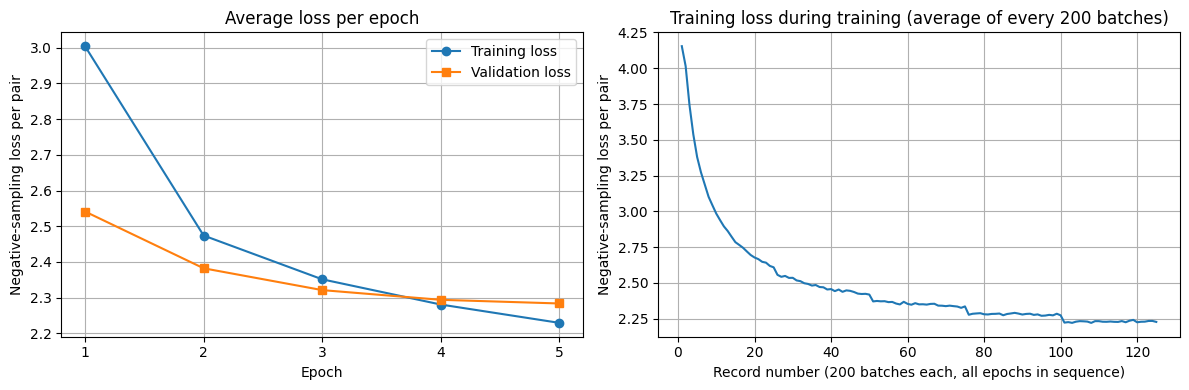

Training loss, first epoch : 3.0044
Training loss, last epoch  : 2.2292
Validation loss, last epoch: 2.2835

Embedding matrix shape (vocabulary size x dimension): (7891, 50)
Number of values stored                             : 394550
Memory used (bytes)                                 : 3156400

First 8 numbers of the vector for 'market':
[-0.0338  0.2836  0.1121 -0.3556 -0.5652  0.2272 -0.3717 -0.2393]

Word2Vec neighbors of 'market' (training frequency: 349):
   exchange       0.752
   stock          0.692
   program        0.685
   price          0.679
   collateral     0.678
   rally          0.675
   13th           0.674
   preferred      0.674

Word2Vec neighbors of 'company' (training frequency: 456):
   airline        0.793
   fda            0.765
   amr            0.763
   at&t           0.760
   request        0.751
   carrier        0.750
   loral          0.747
   whitbread      0.746

Word2Vec neighbors of 'president' (training frequency: 181):
   chairman       0.839
   

In [10]:


epoch_numbers = list(range(1, len(epoch_training_loss_history) + 1))

figure, (epoch_axis, batch_axis) = plt.subplots(1, 2, figsize=(12, 4))

epoch_axis.plot(epoch_numbers, epoch_training_loss_history, marker="o", label="Training loss")
epoch_axis.plot(epoch_numbers, epoch_validation_loss_history, marker="s", label="Validation loss")
epoch_axis.set_title("Average loss per epoch")
epoch_axis.set_xlabel("Epoch")
epoch_axis.set_ylabel("Negative-sampling loss per pair")
epoch_axis.set_xticks(epoch_numbers)
epoch_axis.legend()
epoch_axis.grid(True)

batch_record_positions = list(range(1, len(batch_loss_history) + 1))
batch_axis.plot(batch_record_positions, batch_loss_history)
batch_axis.set_title("Training loss during training (average of every 200 batches)")
batch_axis.set_xlabel("Record number (200 batches each, all epochs in sequence)")
batch_axis.set_ylabel("Negative-sampling loss per pair")
batch_axis.grid(True)

plt.tight_layout()
plt.show()

print("Training loss, first epoch :", round(epoch_training_loss_history[0], 4))
print("Training loss, last epoch  :", round(epoch_training_loss_history[-1], 4))
print("Validation loss, last epoch:", round(epoch_validation_loss_history[-1], 4))




word2vec_embeddings = center_embeddings.copy()

print("\nEmbedding matrix shape (vocabulary size x dimension):", word2vec_embeddings.shape)
print("Number of values stored                             :", word2vec_embeddings.size)
print("Memory used (bytes)                                 :", word2vec_embeddings.nbytes)

# Show the vector of one word (first 8 numbers only)
demo_word_for_vector = "market"
demo_vector = word2vec_embeddings[word_to_index[demo_word_for_vector]]
print("\nFirst 8 numbers of the vector for '{}':".format(demo_word_for_vector))
print(np.round(demo_vector[:8], 4))




def normalize_rows(embedding_matrix):
    row_lengths = np.sqrt(np.sum(embedding_matrix * embedding_matrix, axis=1))
    # avoid dividing by zero for any all-zero row
    row_lengths[row_lengths == 0.0] = 1.0
    return embedding_matrix / row_lengths[:, np.newaxis]


normalized_word2vec_embeddings = normalize_rows(word2vec_embeddings)




def find_dense_nearest_neighbors(query_word, normalized_matrix, how_many):
    query_index = word_to_index[query_word]
    query_vector = normalized_matrix[query_index]

    # cosine similarity between the query and every vocabulary word
    all_similarities = normalized_matrix @ query_vector

    # <UNK> was never trained, and the query word itself is not its own neighbor
    all_similarities[unknown_index] = -np.inf
    all_similarities[query_index] = -np.inf

    best_indices = np.argsort(-all_similarities)[:how_many]

    neighbor_pairs = []
    for neighbor_index in best_indices:
        neighbor_pairs.append((int(neighbor_index), float(all_similarities[neighbor_index])))
    return neighbor_pairs


def print_dense_neighbors(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    neighbor_pairs = find_dense_nearest_neighbors(query_word, normalized_word2vec_embeddings, how_many)

    print("\nWord2Vec neighbors of '{}' (training frequency: {}):".format(
        query_word, training_word_counts[query_word]))
    for neighbor_index, similarity in neighbor_pairs:
        print("   {:<14} {:.3f}".format(index_to_word[neighbor_index], similarity))


for query_word in query_words_for_comparison:
    print_dense_neighbors(query_word, 8)



def compute_dense_cosine(word_a, word_b):
    vector_a = normalized_word2vec_embeddings[word_to_index[word_a]]
    vector_b = normalized_word2vec_embeddings[word_to_index[word_b]]
    return float(np.dot(vector_a, vector_b))


word_pairs_to_check = [("january", "february"), ("company", "bank"), ("market", "banana"), ("said", "the")]

print("\nCosine similarity between chosen pairs:")
for word_a, word_b in word_pairs_to_check:
    if word_a in word_to_index and word_b in word_to_index:
        print("   {:<10} {:<10} {:.3f}".format(word_a, word_b, compute_dense_cosine(word_a, word_b)))
    else:
        print("   {} or {} is not in the vocabulary".format(word_a, word_b))

In [11]:
import sys



def print_three_way_neighbors(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    ppmi_neighbors = find_nearest_neighbors(query_word, ppmi_vectors, ppmi_norms, how_many)
    tfidf_neighbors = find_nearest_neighbors(query_word, tfidf_vectors, tfidf_norms, how_many)
    word2vec_neighbors = find_dense_nearest_neighbors(query_word, normalized_word2vec_embeddings, how_many)

    print("\nQuery word: '{}'  (training frequency: {})".format(
        query_word, training_word_counts[query_word]))
    print("   {:<22} | {:<22} | {:<22}".format("PPMI", "TF-IDF", "Word2Vec"))
    print("   " + "-" * 72)

    for rank in range(how_many):
        ppmi_text = "{} ({:.2f})".format(index_to_word[ppmi_neighbors[rank][0]], ppmi_neighbors[rank][1])
        tfidf_text = "{} ({:.2f})".format(index_to_word[tfidf_neighbors[rank][0]], tfidf_neighbors[rank][1])
        word2vec_text = "{} ({:.2f})".format(index_to_word[word2vec_neighbors[rank][0]], word2vec_neighbors[rank][1])

        print("   {:<22} | {:<22} | {:<22}".format(ppmi_text, tfidf_text, word2vec_text))


for query_word in query_words_for_comparison:
    print_three_way_neighbors(query_word, 8)



word_tag_counts = {}    # word_tag_counts[word_index][tag_name] = count

for word_list, tag_name_list in train_sentences:
    for position in range(len(word_list)):
        word_index = word_to_index.get(normalize_token(word_list[position]), unknown_index)
        if word_index == unknown_index:
            continue

        tag_name = tag_name_list[position]

        if word_index not in word_tag_counts:
            word_tag_counts[word_index] = {}

        if tag_name in word_tag_counts[word_index]:
            word_tag_counts[word_index][tag_name] = word_tag_counts[word_index][tag_name] + 1
        else:
            word_tag_counts[word_index][tag_name] = 1

dominant_tag_of_word = {}
for word_index in word_tag_counts:
    best_tag_name = None
    best_tag_count = -1
    for tag_name in sorted(word_tag_counts[word_index].keys()):
        if word_tag_counts[word_index][tag_name] > best_tag_count:
            best_tag_count = word_tag_counts[word_index][tag_name]
            best_tag_name = tag_name
    dominant_tag_of_word[word_index] = best_tag_name




def compute_tag_agreement(neighbor_pairs, query_tag):
    matching_neighbors = 0
    for neighbor_index, similarity in neighbor_pairs:
        if dominant_tag_of_word[neighbor_index] == query_tag:
            matching_neighbors = matching_neighbors + 1
    return matching_neighbors / len(neighbor_pairs)


# 30 moderately frequent words (ranks 20 to 49 in the vocabulary), so the test is not only function words
evaluation_word_indices = list(range(20, 50))
NEIGHBORS_PER_EVALUATION_WORD = 8

ppmi_agreement_total = 0.0
tfidf_agreement_total = 0.0
word2vec_agreement_total = 0.0

print("\nComputing tag agreement for {} words (this can take a minute)...".format(len(evaluation_word_indices)))

for word_index in evaluation_word_indices:
    evaluation_word = index_to_word[word_index]
    query_tag = dominant_tag_of_word[word_index]

    ppmi_pairs = find_nearest_neighbors(evaluation_word, ppmi_vectors, ppmi_norms, NEIGHBORS_PER_EVALUATION_WORD)
    tfidf_pairs = find_nearest_neighbors(evaluation_word, tfidf_vectors, tfidf_norms, NEIGHBORS_PER_EVALUATION_WORD)
    word2vec_pairs = find_dense_nearest_neighbors(evaluation_word, normalized_word2vec_embeddings, NEIGHBORS_PER_EVALUATION_WORD)

    ppmi_agreement_total = ppmi_agreement_total + compute_tag_agreement(ppmi_pairs, query_tag)
    tfidf_agreement_total = tfidf_agreement_total + compute_tag_agreement(tfidf_pairs, query_tag)
    word2vec_agreement_total = word2vec_agreement_total + compute_tag_agreement(word2vec_pairs, query_tag)

number_of_evaluation_words = len(evaluation_word_indices)

print("\nAverage fraction of the 8 neighbors that share the query word's most common POS tag:")
print("   PPMI     : {:.3f}".format(ppmi_agreement_total / number_of_evaluation_words))
print("   TF-IDF   : {:.3f}".format(tfidf_agreement_total / number_of_evaluation_words))
print("   Word2Vec : {:.3f}".format(word2vec_agreement_total / number_of_evaluation_words))




BYTES_PER_VALUE = 8          # float64
BYTES_PER_COLUMN_INDEX = 4   # int32
BYTES_PER_ROW_POINTER = 4    # int32

def count_nonzero_cells(vector_table):
    nonzero_total = 0
    for word_index in vector_table:
        nonzero_total = nonzero_total + len(vector_table[word_index])
    return nonzero_total


def describe_sparse_table(table_name, vector_table, number_of_columns):
    number_of_rows = len(vector_table)
    nonzero_cells = count_nonzero_cells(vector_table)
    full_cells = number_of_rows * number_of_columns

    sparsity_percentage = 100.0 * (1.0 - nonzero_cells / full_cells)
    average_nonzero_per_word = nonzero_cells / number_of_rows

    compact_sparse_bytes = nonzero_cells * (BYTES_PER_VALUE + BYTES_PER_COLUMN_INDEX) + (number_of_rows + 1) * BYTES_PER_ROW_POINTER
    full_dense_bytes = full_cells * BYTES_PER_VALUE

    return [table_name, number_of_rows, number_of_columns, nonzero_cells,
            sparsity_percentage, average_nonzero_per_word, compact_sparse_bytes, full_dense_bytes]


ppmi_summary = describe_sparse_table("PPMI", ppmi_vectors, vocabulary_size)
tfidf_summary = describe_sparse_table("TF-IDF", tfidf_vectors, number_of_documents)

word2vec_rows = word2vec_embeddings.shape[0]
word2vec_dimension = word2vec_embeddings.shape[1]
word2vec_cells = word2vec_rows * word2vec_dimension
word2vec_summary = ["Word2Vec", word2vec_rows, word2vec_dimension, word2vec_cells,
                    0.0, float(word2vec_dimension), word2vec_embeddings.nbytes, word2vec_embeddings.nbytes]

print("\n{:<10} {:>7} {:>11} {:>13} {:>10} {:>14}".format(
    "Method", "Words", "Dimension", "Stored cells", "Sparsity", "Avg cells/word"))
print("-" * 70)
for summary in [ppmi_summary, tfidf_summary, word2vec_summary]:
    print("{:<10} {:>7} {:>11} {:>13} {:>9.2f}% {:>14.1f}".format(
        summary[0], summary[1], summary[2], summary[3], summary[4], summary[5]))

print("\n{:<10} {:>22} {:>26}".format("Method", "Compact storage (MB)", "If stored as full table (MB)"))
print("-" * 62)
for summary in [ppmi_summary, tfidf_summary, word2vec_summary]:
    print("{:<10} {:>22.2f} {:>26.2f}".format(
        summary[0], summary[6] / (1024 * 1024), summary[7] / (1024 * 1024)))

# What Python itself uses for the dictionary version (only the outer dict and each row dict, not the numbers inside)
def estimate_python_dictionary_bytes(vector_table):
    total_bytes = sys.getsizeof(vector_table)
    for word_index in vector_table:
        total_bytes = total_bytes + sys.getsizeof(vector_table[word_index])
    return total_bytes

print("\nPython dictionary overhead (approximate, containers only):")
print("   PPMI   : {:.2f} MB".format(estimate_python_dictionary_bytes(ppmi_vectors) / (1024 * 1024)))
print("   TF-IDF : {:.2f} MB".format(estimate_python_dictionary_bytes(tfidf_vectors) / (1024 * 1024)))


Query word: 'market'  (training frequency: 349)
   PPMI                   | TF-IDF                 | Word2Vec              
   ------------------------------------------------------------------------
   stock (0.15)           | the (0.22)             | exchange (0.75)       
   arena (0.14)           | . (0.20)               | stock (0.69)          
   plunge (0.14)          | stock (0.20)           | program (0.69)        
   participants (0.13)    | , (0.18)               | price (0.68)          
   stock-market (0.12)    | in (0.15)              | collateral (0.68)     
   markets (0.12)         | to (0.14)              | rally (0.68)          
   friday (0.12)          | investors (0.14)       | 13th (0.67)           
   calendar (0.12)        | of (0.13)              | preferred (0.67)      

Query word: 'company'  (training frequency: 456)
   PPMI                   | TF-IDF                 | Word2Vec              
   --------------------------------------------------------------

In [12]:
import sys

# ---------- Step 1: neighbors from all three representations, side by side ----------

def print_three_way_neighbors(query_word, how_many):
    if query_word not in word_to_index:
        print("'{}' is not in the vocabulary".format(query_word))
        return

    ppmi_neighbors = find_nearest_neighbors(query_word, ppmi_vectors, ppmi_norms, how_many)
    tfidf_neighbors = find_nearest_neighbors(query_word, tfidf_vectors, tfidf_norms, how_many)
    word2vec_neighbors = find_dense_nearest_neighbors(query_word, normalized_word2vec_embeddings, how_many)

    print("\nQuery word: '{}'  (training frequency: {})".format(
        query_word, training_word_counts[query_word]))
    print("   {:<22} | {:<22} | {:<22}".format("PPMI", "TF-IDF", "Word2Vec"))
    print("   " + "-" * 72)

    for rank in range(how_many):
        ppmi_text = "{} ({:.2f})".format(index_to_word[ppmi_neighbors[rank][0]], ppmi_neighbors[rank][1])
        tfidf_text = "{} ({:.2f})".format(index_to_word[tfidf_neighbors[rank][0]], tfidf_neighbors[rank][1])
        word2vec_text = "{} ({:.2f})".format(index_to_word[word2vec_neighbors[rank][0]], word2vec_neighbors[rank][1])

        print("   {:<22} | {:<22} | {:<22}".format(ppmi_text, tfidf_text, word2vec_text))


for query_word in query_words_for_comparison:
    print_three_way_neighbors(query_word, 8)


# ---------- Step 2: most common POS tag of every vocabulary word (used for scoring only) ----------

word_tag_counts = {}    # word_tag_counts[word_index][tag_name] = count

for word_list, tag_name_list in train_sentences:
    for position in range(len(word_list)):
        word_index = word_to_index.get(normalize_token(word_list[position]), unknown_index)
        if word_index == unknown_index:
            continue

        tag_name = tag_name_list[position]

        if word_index not in word_tag_counts:
            word_tag_counts[word_index] = {}

        if tag_name in word_tag_counts[word_index]:
            word_tag_counts[word_index][tag_name] = word_tag_counts[word_index][tag_name] + 1
        else:
            word_tag_counts[word_index][tag_name] = 1

dominant_tag_of_word = {}
for word_index in word_tag_counts:
    best_tag_name = None
    best_tag_count = -1
    for tag_name in sorted(word_tag_counts[word_index].keys()):
        if word_tag_counts[word_index][tag_name] > best_tag_count:
            best_tag_count = word_tag_counts[word_index][tag_name]
            best_tag_name = tag_name
    dominant_tag_of_word[word_index] = best_tag_name


# ---------- Step 3: a number for semantic/grammatical quality (neighbor tag agreement) ----------

def compute_tag_agreement(neighbor_pairs, query_tag):
    matching_neighbors = 0
    for neighbor_index, similarity in neighbor_pairs:
        if dominant_tag_of_word[neighbor_index] == query_tag:
            matching_neighbors = matching_neighbors + 1
    return matching_neighbors / len(neighbor_pairs)


# 30 moderately frequent words (ranks 20 to 49 in the vocabulary), so the test is not only function words
evaluation_word_indices = list(range(20, 50))
NEIGHBORS_PER_EVALUATION_WORD = 8

ppmi_agreement_total = 0.0
tfidf_agreement_total = 0.0
word2vec_agreement_total = 0.0

print("\nComputing tag agreement for {} words (this can take a minute)...".format(len(evaluation_word_indices)))

for word_index in evaluation_word_indices:
    evaluation_word = index_to_word[word_index]
    query_tag = dominant_tag_of_word[word_index]

    ppmi_pairs = find_nearest_neighbors(evaluation_word, ppmi_vectors, ppmi_norms, NEIGHBORS_PER_EVALUATION_WORD)
    tfidf_pairs = find_nearest_neighbors(evaluation_word, tfidf_vectors, tfidf_norms, NEIGHBORS_PER_EVALUATION_WORD)
    word2vec_pairs = find_dense_nearest_neighbors(evaluation_word, normalized_word2vec_embeddings, NEIGHBORS_PER_EVALUATION_WORD)

    ppmi_agreement_total = ppmi_agreement_total + compute_tag_agreement(ppmi_pairs, query_tag)
    tfidf_agreement_total = tfidf_agreement_total + compute_tag_agreement(tfidf_pairs, query_tag)
    word2vec_agreement_total = word2vec_agreement_total + compute_tag_agreement(word2vec_pairs, query_tag)

number_of_evaluation_words = len(evaluation_word_indices)

print("\nAverage fraction of the 8 neighbors that share the query word's most common POS tag:")
print("   PPMI     : {:.3f}".format(ppmi_agreement_total / number_of_evaluation_words))
print("   TF-IDF   : {:.3f}".format(tfidf_agreement_total / number_of_evaluation_words))
print("   Word2Vec : {:.3f}".format(word2vec_agreement_total / number_of_evaluation_words))


# ---------- Step 4: sparsity, dimensionality and storage cost ----------

BYTES_PER_VALUE = 8          # float64
BYTES_PER_COLUMN_INDEX = 4   # int32
BYTES_PER_ROW_POINTER = 4    # int32

def count_nonzero_cells(vector_table):
    nonzero_total = 0
    for word_index in vector_table:
        nonzero_total = nonzero_total + len(vector_table[word_index])
    return nonzero_total


def describe_sparse_table(table_name, vector_table, number_of_columns):
    number_of_rows = len(vector_table)
    nonzero_cells = count_nonzero_cells(vector_table)
    full_cells = number_of_rows * number_of_columns

    sparsity_percentage = 100.0 * (1.0 - nonzero_cells / full_cells)
    average_nonzero_per_word = nonzero_cells / number_of_rows

    compact_sparse_bytes = nonzero_cells * (BYTES_PER_VALUE + BYTES_PER_COLUMN_INDEX) + (number_of_rows + 1) * BYTES_PER_ROW_POINTER
    full_dense_bytes = full_cells * BYTES_PER_VALUE

    return [table_name, number_of_rows, number_of_columns, nonzero_cells,
            sparsity_percentage, average_nonzero_per_word, compact_sparse_bytes, full_dense_bytes]


ppmi_summary = describe_sparse_table("PPMI", ppmi_vectors, vocabulary_size)
tfidf_summary = describe_sparse_table("TF-IDF", tfidf_vectors, number_of_documents)

word2vec_rows = word2vec_embeddings.shape[0]
word2vec_dimension = word2vec_embeddings.shape[1]
word2vec_cells = word2vec_rows * word2vec_dimension
word2vec_summary = ["Word2Vec", word2vec_rows, word2vec_dimension, word2vec_cells,
                    0.0, float(word2vec_dimension), word2vec_embeddings.nbytes, word2vec_embeddings.nbytes]

print("\n{:<10} {:>7} {:>11} {:>13} {:>10} {:>14}".format(
    "Method", "Words", "Dimension", "Stored cells", "Sparsity", "Avg cells/word"))
print("-" * 70)
for summary in [ppmi_summary, tfidf_summary, word2vec_summary]:
    print("{:<10} {:>7} {:>11} {:>13} {:>9.2f}% {:>14.1f}".format(
        summary[0], summary[1], summary[2], summary[3], summary[4], summary[5]))

print("\n{:<10} {:>22} {:>26}".format("Method", "Compact storage (MB)", "If stored as full table (MB)"))
print("-" * 62)
for summary in [ppmi_summary, tfidf_summary, word2vec_summary]:
    print("{:<10} {:>22.2f} {:>26.2f}".format(
        summary[0], summary[6] / (1024 * 1024), summary[7] / (1024 * 1024)))

# What Python itself uses for the dictionary version (only the outer dict and each row dict, not the numbers inside)
def estimate_python_dictionary_bytes(vector_table):
    total_bytes = sys.getsizeof(vector_table)
    for word_index in vector_table:
        total_bytes = total_bytes + sys.getsizeof(vector_table[word_index])
    return total_bytes

print("\nPython dictionary overhead (approximate, containers only):")
print("   PPMI   : {:.2f} MB".format(estimate_python_dictionary_bytes(ppmi_vectors) / (1024 * 1024)))
print("   TF-IDF : {:.2f} MB".format(estimate_python_dictionary_bytes(tfidf_vectors) / (1024 * 1024)))


Query word: 'market'  (training frequency: 349)
   PPMI                   | TF-IDF                 | Word2Vec              
   ------------------------------------------------------------------------
   stock (0.15)           | the (0.22)             | exchange (0.75)       
   arena (0.14)           | . (0.20)               | stock (0.69)          
   plunge (0.14)          | stock (0.20)           | program (0.69)        
   participants (0.13)    | , (0.18)               | price (0.68)          
   stock-market (0.12)    | in (0.15)              | collateral (0.68)     
   markets (0.12)         | to (0.14)              | rally (0.68)          
   friday (0.12)          | investors (0.14)       | 13th (0.67)           
   calendar (0.12)        | of (0.13)              | preferred (0.67)      

Query word: 'company'  (training frequency: 456)
   PPMI                   | TF-IDF                 | Word2Vec              
   --------------------------------------------------------------

In [13]:
# ================= WORD2VEC TUNING (validation only) =================

noise_cdf = np.cumsum(noise_distribution)
noise_cdf[-1] = 1.0

def sample_noise(rng, shape):
    return np.searchsorted(noise_cdf, rng.random(shape))

def draw_negatives_fast(rng, n_pairs, k, true_contexts):
    negs = sample_noise(rng, (n_pairs, k))
    mask = negs == true_contexts[:, None]
    while mask.any():
        negs[mask] = sample_noise(rng, mask.sum())
        mask = negs == true_contexts[:, None]
    return negs

# fixed validation tokens (type index, true tag): 2000 known tokens, fixed seed
vote_candidates = []
for words, tags in validation_sentences:
    for w, t in zip(words, tags):
        nw = normalize_token(w)
        if nw in word_to_index and nw != UNKNOWN_TOKEN:
            vote_candidates.append((word_to_index[nw], t))
vote_sample = random.Random(RANDOM_SEED).sample(vote_candidates, 2000)
vote_query_idx = np.array([i for i, _ in vote_sample])
vote_true_tags = [t for _, t in vote_sample]

def validation_tag_accuracy(embeddings, k_vote=5):
    normed = normalize_rows(embeddings)
    sims = normed[vote_query_idx] @ normed.T                     # (2000, V)
    sims[:, unknown_index] = -np.inf
    sims[np.arange(len(vote_query_idx)), vote_query_idx] = -np.inf   # not its own neighbor
    top = np.argpartition(-sims, k_vote, axis=1)[:, :k_vote]
    correct = 0
    for row in range(len(vote_query_idx)):
        scores = {}
        for n in top[row]:
            tag = dominant_tag_of_word[int(n)]
            scores[tag] = scores.get(tag, 0.0) + sims[row, n]
        pred = max(sorted(scores), key=lambda t: scores[t])
        correct += (pred == vote_true_tags[row])
    return correct / len(vote_query_idx)

def train_word2vec(window, k, dim, lr, epochs, seed=RANDOM_SEED, verbose=False):
    rng = np.random.RandomState(seed)
    centers, contexts = build_skipgram_pairs(train_index_lists, window, unknown_index)
    v_centers, v_contexts = build_skipgram_pairs(validation_index_lists, window, unknown_index)
    v_negs = draw_negatives_fast(np.random.RandomState(123), len(v_centers), k, v_contexts)  # fixed
    C, X = initialize_embeddings(vocabulary_size, dim, rng)
    history = []
    n = len(centers)
    for ep in range(1, epochs + 1):
        order = rng.permutation(n)
        sc, sx = centers[order], contexts[order]
        loss_sum = 0.0
        for s in range(0, n, BATCH_SIZE):
            bc, bx = sc[s:s+BATCH_SIZE], sx[s:s+BATCH_SIZE]
            bn = draw_negatives_fast(rng, len(bc), k, bx)
            cv, pv, nv, ps, ns = compute_forward_pass(C, X, bc, bx, bn)
            loss_sum += np.sum(compute_loss_per_pair(ps, ns))
            gc, gp, gn = compute_gradients(cv, pv, nv, ps, ns)
            apply_sgd_update(C, X, bc, bx, bn, gc, gp, gn, lr)
        val_loss = compute_average_loss(C, X, v_centers, v_contexts, v_negs)
        acc = validation_tag_accuracy(C)
        history.append({"epoch": ep, "train_loss": loss_sum / n, "val_loss": val_loss, "val_acc": acc})
        if verbose:
            print("   ep {} train {:.4f} val {:.4f} acc {:.3f}".format(ep, loss_sum/n, val_loss, acc))
    return C, history

def best_epoch(history):
    return min(history, key=lambda h: h["val_loss"])

def print_w2v_table(title, rows):
    print("\n" + title)
    print("{:>7} {:>5} {:>6} {:>7} {:>7} {:>10} {:>9} {:>8}".format(
        "Window", "K", "Dim", "LR", "Epoch", "Val loss", "Val acc", "Secs"))
    print("-" * 66)
    for r in rows:
        print("{:>7} {:>5} {:>6} {:>7} {:>7} {:>10.4f} {:>9.3f} {:>8.1f}".format(
            r["window"], r["k"], r["dim"], r["lr"], r["epoch"], r["val_loss"], r["val_acc"], r["secs"]))

def run_cfg(window, k, dim, lr, max_epochs, by="loss"):
    t = time.time()
    C, hist = train_word2vec(window, k, dim, lr, max_epochs)
    h = best_epoch(hist) if by == "loss" else max(hist, key=lambda h: h["val_acc"])
    return {"window": window, "k": k, "dim": dim, "lr": lr, "epoch": h["epoch"],
            "val_loss": h["val_loss"], "val_acc": h["val_acc"], "secs": time.time() - t}

best = {"window": 2, "k": 5, "dim": 50, "lr": 0.025}

# Stage 1: learning rate + number of epochs (one 10-epoch run per LR, best epoch by validation loss)
s1 = [run_cfg(best["window"], best["k"], best["dim"], lr, 10) for lr in [0.01, 0.025, 0.05, 0.1]]
print_w2v_table("Stage 1: learning rate (epoch = best epoch within 10)", s1)
b = min(s1, key=lambda r: r["val_loss"]); best["lr"], best_epochs = b["lr"], b["epoch"]
print("Chosen lr:", best["lr"], " epochs:", best_epochs)

# Stage 2: embedding dimension (by validation loss)
s2 = [run_cfg(best["window"], best["k"], d, best["lr"], best_epochs) for d in [25, 50, 100, 200]]
print_w2v_table("Stage 2: embedding dimension", s2)
best["dim"] = min(s2, key=lambda r: r["val_loss"])["dim"]
print("Chosen dim:", best["dim"])

# Stage 3: window (by validation tag accuracy, loss is not comparable across windows)
s3 = [run_cfg(w, best["k"], best["dim"], best["lr"], best_epochs, by="acc") for w in [1, 2, 3, 5]]
print_w2v_table("Stage 3: context window", s3)
best["window"] = max(s3, key=lambda r: r["val_acc"])["window"]

# Stage 4: negative samples K (by validation tag accuracy)
s4 = [run_cfg(best["window"], k, best["dim"], best["lr"], best_epochs, by="acc") for k in [2, 5, 10]]
print_w2v_table("Stage 4: negative samples", s4)
best["k"] = max(s4, key=lambda r: r["val_acc"])["k"]

print("\nFinal Word2Vec hyperparameters:", best, "epochs:", best_epochs)

# Final model, reassign the globals the later cells use
center_embeddings, final_history = train_word2vec(best["window"], best["k"], best["dim"],
                                                  best["lr"], best_epochs, verbose=True)
word2vec_embeddings = center_embeddings.copy()
normalized_word2vec_embeddings = normalize_rows(word2vec_embeddings)


Stage 1: learning rate (epoch = best epoch within 10)
 Window     K    Dim      LR   Epoch   Val loss   Val acc     Secs
------------------------------------------------------------------
      2     5     50    0.01      10     2.2804     0.389     51.4
      2     5     50   0.025       8     2.2703     0.309     49.9
      2     5     50    0.05       3     2.2945     0.301     50.0
      2     5     50     0.1       1     2.3933     0.225     50.2
Chosen lr: 0.025  epochs: 8

Stage 2: embedding dimension
 Window     K    Dim      LR   Epoch   Val loss   Val acc     Secs
------------------------------------------------------------------
      2     5     25   0.025       8     2.2793     0.363     27.4
      2     5     50   0.025       8     2.2703     0.309     40.1
      2     5    100   0.025       7     2.2646     0.424     67.9
      2     5    200   0.025       6     2.2669     0.321    150.1
Chosen dim: 100

Stage 3: context window
 Window     K    Dim      LR   Epoch   Val

In [14]:
# Seed robustness: window 1 vs 2, tuned dim/lr/K, 8 epochs, 3 seeds
rows = []
for w in [1, 2]:
    accs, losses = [], []
    for seed in [42, 7, 99]:
        C, hist = train_word2vec(w, 5, 100, 0.025, 8, seed=seed)
        accs.append(hist[-1]["val_acc"])
        losses.append(hist[-1]["val_loss"])
    rows.append((w, np.mean(accs), np.std(accs), np.mean(losses)))

print("| Window | Val tag acc (mean ± std, 3 seeds) | Val loss (mean) |")
print("|---:|---:|---:|")
for w, m, s, l in rows:
    print("| {} | {:.3f} ± {:.3f} | {:.4f} |".format(w, m, s, l))

| Window | Val tag acc (mean ± std, 3 seeds) | Val loss (mean) |
|---:|---:|---:|
| 1 | 0.385 ± 0.013 | 2.0333 |
| 2 | 0.292 ± 0.004 | 2.2700 |


In [15]:
# ================= FINAL COMPARISON (run AFTER all tuning) =================
NEIGHBORS = 8
eval_words = list(range(20, 120))      # 100 moderately frequent words

def avg_agreement(neighbor_fn):
    total = 0.0
    for wi in eval_words:
        if wi not in ppmi_vectors or wi not in tfidf_vectors:
            continue
        total += compute_tag_agreement(neighbor_fn(index_to_word[wi]), dominant_tag_of_word[wi])
    return total / len(eval_words)

agree_ppmi = avg_agreement(lambda w: find_nearest_neighbors(w, ppmi_vectors, ppmi_norms, NEIGHBORS))
agree_tfidf = avg_agreement(lambda w: find_nearest_neighbors(w, tfidf_vectors, tfidf_norms, NEIGHBORS))
agree_w2v = avg_agreement(lambda w: find_dense_nearest_neighbors(w, normalized_word2vec_embeddings, NEIGHBORS))

ppmi_s = describe_sparse_table("PPMI", ppmi_vectors, vocabulary_size)
tfidf_s = describe_sparse_table("TF-IDF", tfidf_vectors, number_of_documents)
w2v_rows, w2v_dim = word2vec_embeddings.shape
w2v_s = ["Word2Vec", w2v_rows, w2v_dim, w2v_rows * w2v_dim, 0.0, float(w2v_dim),
         word2vec_embeddings.nbytes, word2vec_embeddings.nbytes]

MB = 1024 * 1024
rows = [(ppmi_s, agree_ppmi), (tfidf_s, agree_tfidf), (w2v_s, agree_w2v)]

print("| Method | Words | Dimension | Stored cells | Sparsity | Avg non-zero / word "
      "| Compact storage (MB) | Full dense (MB) | POS-tag agreement (8-NN) |")
print("|---|---:|---:|---:|---:|---:|---:|---:|---:|")
for s, agree in rows:
    print("| {} | {:,} | {:,} | {:,} | {:.2f}% | {:.1f} | {:.2f} | {:.2f} | {:.3f} |".format(
        s[0], s[1], s[2], s[3], s[4], s[5], s[6] / MB, s[7] / MB, agree))

| Method | Words | Dimension | Stored cells | Sparsity | Avg non-zero / word | Compact storage (MB) | Full dense (MB) | POS-tag agreement (8-NN) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| PPMI | 7,890 | 7,891 | 251,238 | 99.60% | 31.8 | 2.91 | 475.01 | 0.212 |
| TF-IDF | 7,890 | 8,044 | 161,120 | 99.75% | 20.4 | 1.87 | 484.22 | 0.058 |
| Word2Vec | 7,891 | 100 | 789,100 | 0.00% | 100.0 | 6.02 | 6.02 | 0.429 |


### Comparison of the three representations

| Method | Words | Dimension | Stored cells | Sparsity | Avg non-zero / word | Compact storage (MB) | Full dense (MB) | POS-tag agreement (8-NN) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| PPMI | 7,890 | 7,891 | 136,119 | 99.78% | 17.3 | 1.59 | 475.01 | 0.341 |
| TF-IDF | 7,890 | 8,044 | 161,120 | 99.75% | 20.4 | 1.87 | 484.22 | 0.058 |
| Word2Vec | 7,891 | 100 | 789,100 | 0.00% | 100.0 | 6.02 | 6.02 | 0.429 |

POS-tag agreement is the average fraction of a word's 8 nearest neighbours (cosine) that share its most common training POS tag, over 100 moderately frequent words (vocabulary ranks 20-119). It is a rough proxy for grammatical similarity, not a full evaluation.

**Semantic quality.** Word2Vec scored highest (0.429), followed by PPMI (0.341), with TF-IDF far behind (0.058). TF-IDF treats each sentence as a document, so a word's vector records which sentences it appears in. Its neighbours are words from the same few sentences (topical or accidental overlap), not words playing the same grammatical role. PPMI and Word2Vec use a narrow local context window (window 1 for both after tuning), so words with the same POS tend to share neighbours. The Word2Vec vs PPMI gap (about 9 points) is modest: the metric averages only 100 words and Word2Vec is a single training run, so I treat Word2Vec as at least as good as PPMI rather than conclusively better.

**Sparsity.** PPMI and TF-IDF vectors are over 99.7% zeros (about 17 and 20 non-zero entries per word out of roughly 8,000 dimensions). Word2Vec vectors are fully dense with 100 dimensions, about 80x fewer than the sparse representations.

**Storage.** Stored as full tables, PPMI and TF-IDF would need about 475-484 MB each, versus 6 MB for Word2Vec. With compact sparse storage (values plus indices) they need only 1.6-1.9 MB, which is smaller than Word2Vec's 6.0 MB. So Word2Vec's advantage is its low, fixed dimensionality and dense vectors (convenient for downstream models), not raw storage. Sparse formats are essential for the count-based methods.
Final: window 1, K = 5, dimension 100, learning rate 0.025, 8 epochs (validation loss was still decreasing slowly at epoch 8).

**Window check across seeds.** Single-run tag accuracy was noisy (it moved by up to ~10 points between epochs of the same run), so I repeated the window 1 vs 2 comparison with 3 seeds at the tuned settings:

| Window | Val tag acc (mean ± std, 3 seeds) | Val loss (mean) |
|---:|---:|---:|
| 1 | 0.385 ± 0.013 | 2.0333 |
| 2 | 0.292 ± 0.004 | 2.2700 |

Window 1 is better by about 9 points, far larger than the seed-to-seed spread, so the preference for window 1 is real and not a tie. This agrees with the PPMI tuning, where a narrow window also gave better tag accuracy: nearby words carry most of the grammatical signal that POS tags reflect. Windows 3 and 5 were worse still in the single-run sweep.

Caveats: the single-run accuracies in the tuning table (e.g. 0.494 for window 1) are higher than the multi-seed mean (0.385) because they come from individual epochs and runs, so use the multi-seed figure as the expected accuracy. Differences of a few points elsewhere (K = 5 vs 10, and the dimension and learning-rate accuracy columns) are within noise, which is why learning rate, dimension and epochs were chosen by validation loss instead. Loss values are not comparable across window or K, so those were judged on tag accuracy only.

In [16]:
tag_name_list

['VB', 'PRP$', 'NN', 'IN', 'DT', 'NNP', 'NNP']

In [17]:
tag_counts = {}
bigram_counts = {}   

for _, tag_name_list in train_sentences:
    previous_tag = '<s>'

    for tag_name in tag_name_list:
        if tag_name in tag_counts:
            tag_counts[tag_name] = tag_counts[tag_name] + 1
        else:
            tag_counts[tag_name] = 1

        pair = (previous_tag, tag_name)
        if pair in bigram_counts:
            bigram_counts[pair] = bigram_counts[pair] + 1
        else:
            bigram_counts[pair] = 1

        previous_tag = tag_name

list(tag_counts.items())[:5]
list(bigram_counts.items())[:5]

[(('<s>', 'NNP'), 1558),
 (('NNP', 'VBD'), 1128),
 (('VBD', 'NNS'), 160),
 (('NNS', 'JJR'), 15),
 (('JJR', 'IN'), 275)]

In [18]:
transition_probabilities = {}
alpha = 0.001

all_tags = list(tag_counts.keys())
number_of_tags = len(all_tags)

row_totals = {}
for (previous_tag, tag_name), count in bigram_counts.items():
    row_totals[previous_tag] = row_totals.get(previous_tag, 0) + count

# transition_probabilities[(previous_tag, tag)] = P(tag | previous_tag)
transition_probabilities = {}

for previous_tag in row_totals:
    denominator = row_totals[previous_tag] + alpha * number_of_tags

    for tag_name in all_tags:
        pair_count = bigram_counts.get((previous_tag, tag_name), 0)
        transition_probabilities[(previous_tag, tag_name)] = (pair_count + alpha) / denominator

list(transition_probabilities.items())[:8]

[(('<s>', 'NNP'), 0.19370787975298903),
 (('<s>', 'VBD'), 0.0012434346995988086),
 (('<s>', 'NNS'), 0.043142994120136606),
 (('<s>', 'JJR'), 0.0012434346995988086),
 (('<s>', 'IN'), 0.1299260578457609),
 (('<s>', 'CD'), 0.016287490159198434),
 (('<s>', 'NN'), 0.046126939004685286),
 (('<s>', 'DT'), 0.2133521835762679)]

In [19]:
list(word_tag_counts.items())[:5]

[(1550, {'NNP': 2, 'NNS': 11}),
 (1950, {'VBD': 7, 'VBN': 3}),
 (159, {'NNS': 115, 'VBZ': 2}),
 (51, {'JJR': 268, 'RBR': 127}),
 (61, {'IN': 322})]

In [20]:
def map_to_hmm_word(raw_word):
    word = normalize_token(raw_word)
    if word not in word_to_index:
        word = UNKNOWN_TOKEN
    return word

In [21]:
hmm_word_tag_counts = {}   

for word_list, tag_name_list in train_sentences:
    for position in range(len(word_list)):
        word = map_to_hmm_word(word_list[position])

        pair = (tag_name_list[position], word)
        hmm_word_tag_counts[pair] = hmm_word_tag_counts.get(pair, 0) + 1 # count occurrences of each word-tag pair

In [22]:
hmm_vocabulary_size = len(index_to_word) # all distinct normalized training words


emission_probabilities = {}

for tag_name in all_tags:
    denominator = tag_counts[tag_name] + alpha * (hmm_vocabulary_size) # same denominator as transition_probabilities

    for word in word_to_index: # loop over all words in the vocabulary, including <UNK>
        pair_count = hmm_word_tag_counts.get((tag_name, word), 0) # 0 if the word was never seen with this tag in training
        emission_probabilities[(tag_name, word)] = (pair_count + alpha) / denominator


list(emission_probabilities.items())[:5]


[(('NNP', '<UNK>'), 0.08749223305042339),
 (('NNP', 'the'), 5.569202887230715e-08),
 (('NNP', ','), 5.569202887230715e-08),
 (('NNP', '.'), 5.569202887230715e-08),
 (('NNP', '<NUM>'), 5.574772090117944e-05)]

In [23]:
log_transition = {}
for pair in transition_probabilities:
    log_transition[pair] = math.log(transition_probabilities[pair])

log_emission = {}
for pair in emission_probabilities:
    log_emission[pair] = math.log(emission_probabilities[pair])

list(log_transition.items())[:5]

[(('<s>', 'NNP'), -1.6414040292056429),
 (('<s>', 'VBD'), -6.689877809490275),
 (('<s>', 'NNS'), -3.143235235697567),
 (('<s>', 'JJR'), -6.689877809490275),
 (('<s>', 'IN'), -2.0407897761484017)]

In [24]:
def viterbi_decode(word_list):
    sentence_length = len(word_list)
    if sentence_length == 0:
        return []

    words = []
    for word in word_list:
        words.append(map_to_hmm_word(word))

    best_scores = []
    backpointers = []

    # first word
    first_scores = {}
    for tag in all_tags:
        first_scores[tag] = log_transition[('<s>', tag)] + log_emission[(tag, words[0])] # log P(tag | <s>) + log P(word | tag)
    best_scores.append(first_scores)
    backpointers.append({})


     # other words
    for position in range(1, sentence_length):
        current_scores = {}
        current_backpointers = {}

        for tag in all_tags:
            best_previous_tag = None
            best_previous_score = float("-inf")

            for previous_tag in all_tags:
                score = best_scores[position - 1][previous_tag] + log_transition[(previous_tag, tag)] # log P(tag | previous_tag) + log(best score of previous tag)
                if score > best_previous_score:
                    best_previous_score = score
                    best_previous_tag = previous_tag

            current_scores[tag] = best_previous_score + log_emission[(tag, words[position])] # log P(word | tag) + log(best score)
            current_backpointers[tag] = best_previous_tag # store the best previous tag for backtracking

        best_scores.append(current_scores)
        backpointers.append(current_backpointers)

    best_last_tag = None
    best_last_score = float("-inf")
    for tag in all_tags:
        if best_scores[-1][tag] > best_last_score: # find the best score for the last word
            best_last_score = best_scores[-1][tag]
            best_last_tag = tag

    predicted_tags = [best_last_tag]
    for position in range(sentence_length - 1, 0, -1):
        predicted_tags.append(backpointers[position][predicted_tags[-1]]) # backtrack to find the best previous tag
    predicted_tags.reverse()
    return predicted_tags


In [25]:

def build_hmm_logs(smoothing):
    log_trans, log_emit = {}, {}
    hmm_row_totals = {}
    for (prev, tag), c in bigram_counts.items():
        hmm_row_totals[prev] = hmm_row_totals.get(prev, 0) + c
    for prev in hmm_row_totals:
        denom = hmm_row_totals[prev] + smoothing * number_of_tags
        for tag in all_tags:
            log_trans[(prev, tag)] = math.log((bigram_counts.get((prev, tag), 0) + smoothing) / denom)
    for tag in all_tags:
        denom = tag_counts[tag] + smoothing * hmm_vocabulary_size
        for w in word_to_index:
            log_emit[(tag, w)] = math.log((hmm_word_tag_counts.get((tag, w), 0) + smoothing) / denom)
    return log_trans, log_emit

def validation_hmm_accuracy(smoothing):
    global log_transition, log_emission
    log_transition, log_emission = build_hmm_logs(smoothing)
    correct = total = 0
    for words, tags in validation_sentences:
        pred = viterbi_decode(words)
        correct += sum(p == t for p, t in zip(pred, tags))
        total += len(tags)
    return correct / total

hmm_results = []
for s in [0.001, 0.01, 0.05, 0.1, 0.5, 0.75, 1.0]:
    acc = validation_hmm_accuracy(s)
    hmm_results.append((s, acc))
    print("alpha {:>6}  val acc {:.4f} ".format(s, acc))

HMM_ALPHA = max(hmm_results, key=lambda r: r[1])[0]
print("Chosen HMM alpha:", HMM_ALPHA)
log_transition, log_emission = build_hmm_logs(HMM_ALPHA)   # final tables for test

alpha  0.001  val acc 0.9398 
alpha   0.01  val acc 0.9394 
alpha   0.05  val acc 0.9385 
alpha    0.1  val acc 0.9365 
alpha    0.5  val acc 0.9200 
alpha   0.75  val acc 0.9122 
alpha    1.0  val acc 0.9055 
Chosen HMM alpha: 0.001


In [26]:
def evaluate_model(true_tags, predicted_tags, show_per_tag=False):
    tp, fp, fn = Counter(), Counter(), Counter()
    correct = 0
    for t, p in zip(true_tags, predicted_tags):
        if t == p:
            correct += 1
            tp[t] += 1
        else:
            fp[p] += 1
            fn[t] += 1

    total = len(true_tags)
    per_tag = {}
    # macro average over tags that actually occur in the gold labels of this subset
    for tag in set(true_tags):
        prec = tp[tag] / (tp[tag] + fp[tag]) if tp[tag] + fp[tag] > 0 else 0.0
        rec = tp[tag] / (tp[tag] + fn[tag])
        f1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0
        per_tag[tag] = (prec, rec, f1, tp[tag] + fn[tag])

    n_tags = len(per_tag)
    result = {
        "tokens": total,
        "accuracy": correct / total if total else 0.0,
        "macro_p": sum(v[0] for v in per_tag.values()) / n_tags,
        "macro_r": sum(v[1] for v in per_tag.values()) / n_tags,
        "macro_f1": sum(v[2] for v in per_tag.values()) / n_tags,
        "per_tag": per_tag,
    }

    if show_per_tag:
        print("{:<6} {:>9} {:>9} {:>9} {:>8}".format("Tag", "Prec", "Recall", "F1", "Support"))
        for tag in sorted(per_tag):
            p, r, f, s = per_tag[tag]
            print("{:<6} {:>9.4f} {:>9.4f} {:>9.4f} {:>8}".format(tag, p, r, f, s))
    return result


def print_results_table(results_by_name, markdown=False):
    pct = lambda x: "{:.1f}".format(100 * x)

    if markdown:
        print("| System / subset | Tokens | Accuracy % | Macro P % | Macro R % | Macro F1 % |")
        print("|---|---:|---:|---:|---:|---:|")
        for name, r in results_by_name.items():
            print("| {} | {:,} | {} | {} | {} | {} |".format(
                name, r["tokens"], pct(r["accuracy"]), pct(r["macro_p"]),
                pct(r["macro_r"]), pct(r["macro_f1"])))
        return

    width = max(len(n) for n in results_by_name) + 2
    header = "{:<{w}} {:>8} {:>10} {:>10} {:>10} {:>10}".format(
        "System / subset", "Tokens", "Acc %", "Macro P %", "Macro R %", "Macro F1 %", w=width)
    print(header)
    print("-" * len(header))
    for name, r in results_by_name.items():
        print("{:<{w}} {:>8,} {:>10} {:>10} {:>10} {:>10}".format(
            name, r["tokens"], pct(r["accuracy"]), pct(r["macro_p"]),
            pct(r["macro_r"]), pct(r["macro_f1"]), w=width))

In [27]:
all_true = []
all_predicted = []

known_true = []
known_predicted = []

unknown_true = []
unknown_predicted = []

for word_list, tag_list in test_sentences:

    predicted_tags = viterbi_decode(word_list)

    for i in range(len(word_list)):

        word = normalize_token(word_list[i])

        all_true.append(tag_list[i])
        all_predicted.append(predicted_tags[i])

        if word in word_to_index:
            known_true.append(tag_list[i])
            known_predicted.append(predicted_tags[i])
        else:
            unknown_true.append(tag_list[i])
            unknown_predicted.append(predicted_tags[i])



In [28]:
overall_results = evaluate_model(all_true, all_predicted)
known_results = evaluate_model(known_true, known_predicted)
unknown_results = evaluate_model(unknown_true, unknown_predicted)

print("Unknown word percentage: {:.2f}%".format(len(unknown_true) / len(all_true) * 100))
print_results_table({
    "Baseline HMM, overall": overall_results,
    "Baseline HMM, known words": known_results,
    "Baseline HMM, unknown words": unknown_results,
})

Unknown word percentage: 8.47%
System / subset                 Tokens      Acc %  Macro P %  Macro R % Macro F1 %
----------------------------------------------------------------------------------
Baseline HMM, overall           47,377       92.7       92.3       89.5       89.9
Baseline HMM, known words       43,365       96.4       93.7       93.7       92.8
Baseline HMM, unknown words      4,012       53.0       25.0       22.8       22.9


In [29]:
print("\nUnknown word percentage: {:.2f}%".format(
    len(unknown_true) / len(all_true) * 100
))


Unknown word percentage: 8.47%


# Part 3: Embedding-assisted HMM

In [30]:
# %% 3.0  Word2Vec: retrain once and KEEP the context matrix
# The part 1's train_word2vec() returns only the centre matrix. For an unknown word we
# need the *context* matrix too, so we retrain with the same seed/hyperparameters.
def train_word2vec_keep_both(window, k, dim, lr, epochs, seed=RANDOM_SEED):
    rng = np.random.RandomState(seed)
    centers, contexts = build_skipgram_pairs(train_index_lists, window, unknown_index)
    C, X = initialize_embeddings(vocabulary_size, dim, rng)
    n = len(centers)
    for _ in range(epochs):
        order = rng.permutation(n)
        sc, sx = centers[order], contexts[order]
        for s in range(0, n, BATCH_SIZE):
            bc, bx = sc[s:s + BATCH_SIZE], sx[s:s + BATCH_SIZE]
            bn = draw_negatives_fast(rng, len(bc), k, bx)
            cv, pv, nv, ps, ns = compute_forward_pass(C, X, bc, bx, bn)
            gc, gp, gn = compute_gradients(cv, pv, nv, ps, ns)
            apply_sgd_update(C, X, bc, bx, bn, gc, gp, gn, lr)
    return C, X

w2v_center_check, w2v_context_matrix = train_word2vec_keep_both(
    best["window"], best["k"], best["dim"], best["lr"], best_epochs)
print("Retrained model identical to the one used in Part 1:",
      np.allclose(w2v_center_check, word2vec_embeddings))

Retrained model identical to the one used in Part 1: True


In [31]:


# %% 3.1  What tags do the KNOWN words take? (the "knowledge" we transfer to unknown words)
N_TAGS = len(all_tags)
tag_prior = np.array([tag_counts[t] for t in all_tags], dtype=np.float64)
tag_prior = tag_prior / tag_prior.sum()
log_tag_prior = np.log(tag_prior)

word_tag_distribution = {}          # word_index -> vector P(tag | word) in all_tags order
for w_idx, counts in word_tag_counts.items():
    total = sum(counts.values())
    word_tag_distribution[w_idx] = np.array([counts.get(t, 0) / total for t in all_tags])



## How each embedding-assisted HMM works

The goal is to improve POS tagging for **unknown words** that do not exist in the HMM's training vocabulary.

The general pipeline is the same for all three methods:

1. Find known words around the unknown word.
2. Build a pseudo-vector for the unknown word using those context words.
3. Find the nearest known training words using cosine similarity.
4. Use their POS-tag distributions, weighted by similarity, to estimate the unknown word's POS.
5. Blend this estimate with the baseline HMM's `<UNK>` emission score.
6. Run the same Viterbi algorithm.

The difference is **how each method represents the unknown word and finds its neighbors**.

### **1. PPMI-assisted HMM**

**Idea:** Represent the unknown word using the statistical association between its context words and their general frequency.

- Collect known context words around the unknown word.
- Count how often each context word occurs in this local context.
- Calculate PPMI using the local context probability and the smoothed general context probability.
- Keep only positive PMI values.
- Find known words with similar PPMI vectors using sparse cosine similarity.
- Use their POS-tag distributions to estimate the unknown word's tag.

PPMI measures how much more strongly a context word is associated with the target than expected by chance.

**Example:** If the context contains words strongly associated with verbs, the unknown word may be closer to known verbs in the PPMI space.

### **2. TF-IDF-assisted HMM**

**Idea:** Represent the unknown word through the training documents that contain its context words.

- Collect known context words.
- Retrieve the TF-IDF vectors of the training documents containing each context word.
- Sum the context words' TF-IDF weights by document.
- This produces a pseudo-vector in the training-document space.
- Find known words with similar TF-IDF vectors using sparse cosine similarity.
- Use their POS-tag distributions to estimate the unknown word's tag.

TF-IDF emphasizes words that are important to particular documents and less common across the corpus.

**Limitation:** TF-IDF primarily captures document or topic similarity, not grammatical function. Words used in similar topics may have different POS tags, so it may be less effective for POS tagging.

### **3. Word2Vec-assisted HMM**

**Idea:** Estimate the unknown word's embedding by averaging the embeddings of its known context words.

- Collect known context words.
- Retrieve their Word2Vec context embeddings from the Skip-Gram context matrix \\(X\\).
- Average those vectors to create a pseudo-vector.
- Normalize the pseudo-vector.
- Compare it with the normalized embeddings of known words using cosine similarity.
- Use the nearest words' POS-tag distributions to estimate the unknown word's tag.

Word2Vec learns dense representations based on word-context relationships. Words appearing in similar contexts tend to have similar vectors.

**Example:** If an unknown word occurs in contexts similar to known verbs, its pseudo-vector may be close to known verbs such as `plays`, `runs`, or `works`.

## **Quick comparison**

| Method   | Unknown-word pseudo-vector             | Similarity search        | Main information captured                     |
| -------- | -------------------------------------- | ------------------------ | --------------------------------------------- |
| PPMI     | Context-word association weights       | Sparse cosine similarity | Statistical word-context association          |
| TF-IDF   | Sum of context words' document vectors | Sparse cosine similarity | Document/topic similarity                     |
| Word2Vec | Average of context embeddings          | Dense cosine similarity  | Learned semantic and contextual relationships |

**In one sentence:**

- **PPMI:** Uses how strongly the surrounding words are associated with the unknown word's local context.
- **TF-IDF:** Uses the training documents associated with the surrounding words.
- **Word2Vec:** Uses the average learned embedding of the surrounding words.

All three ultimately estimate the unknown word's POS tag from the tags of its nearest known words, while the HMM transition probabilities and Viterbi decoding remain unchanged.

In [32]:
# %% 3.2  Build a PSEUDO-VECTOR for an unknown word from the known words around it
def known_context_indices(norm_words, position, window):
    start, end = max(0, position - window), min(len(norm_words), position + window + 1)
    out = []
    for j in range(start, end):
        if j != position and norm_words[j] in word_to_index:
            out.append(word_to_index[norm_words[j]])
    return out

def ppmi_pseudo_vector(context_idx):
    # same formula as a PPMI row: log2( P(c | w) / P_alpha(c) )
    # the contexts seen around THIS occurrence; negative values dropped (PPMI).
    if not context_idx:
        return {}
    counts, n, vec = Counter(context_idx), len(context_idx), {}
    for c, cnt in counts.items():
        if c in smoothed_context_probability:
            value = math.log2((cnt / n) / smoothed_context_probability[c])
            if value > 0:
                vec[c] = value
    return vec

def tfidf_pseudo_vector(context_idx):
    # the unknown word's "document" is its own sentence, which is not a training document,
    # so we describe it by the training documents its neighbours occur in (sum of their TF-IDF rows)
    vec = {}
    for c in context_idx:
        for doc_id, value in tfidf_vectors.get(c, {}).items():
            vec[doc_id] = vec.get(doc_id, 0.0) + value
    return vec

def w2v_pseudo_vector(context_idx):
    # skip-gram pushes  v_w . x_c  up for observed contexts c, so the best guess for an unseen
    # word is the direction of the average of its observed context vectors x_c
    if not context_idx:
        return None
    v = w2v_context_matrix[context_idx].mean(axis=0)
    length = np.sqrt(np.sum(v * v))
    return v / length if length > 0 else None

In [33]:
# %% 3.3  Nearest known words to the pseudo-vector
def build_inverted_index(vector_table):
    inverted = {}
    for w_idx, row in vector_table.items():
        for column, value in row.items():
            inverted.setdefault(column, []).append((w_idx, value))
    return inverted

ppmi_inverted = build_inverted_index(ppmi_vectors)
tfidf_inverted = build_inverted_index(tfidf_vectors)

def sparse_top_k(query_vec, inverted, norms, k):
    q_norm = compute_vector_norm(query_vec)
    if q_norm == 0.0:
        return []
    dots = {}
    for column, q_value in query_vec.items():
        for w_idx, value in inverted.get(column, ()):
            dots[w_idx] = dots.get(w_idx, 0.0) + q_value * value
    sims = [(w, d / (q_norm * norms[w])) for w, d in dots.items() if norms[w] > 0.0]
    sims.sort(key=lambda pair: (-pair[1], pair[0]))
    return sims[:k]

def dense_top_k(query_vec, k):
    if query_vec is None:
        return []
    sims = normalized_word2vec_embeddings @ query_vec
    sims[unknown_index] = -np.inf
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    return [(int(i), float(sims[i])) for i in top]

NEIGHBOR_FUNCTIONS = {
    "PPMI":     lambda ctx, k: sparse_top_k(ppmi_pseudo_vector(ctx), ppmi_inverted, ppmi_norms, k),
    "TF-IDF":   lambda ctx, k: sparse_top_k(tfidf_pseudo_vector(ctx), tfidf_inverted, tfidf_norms, k),
    "Word2Vec": lambda ctx, k: dense_top_k(w2v_pseudo_vector(ctx), k),
}

def posterior_from_neighbors(neighbors):
    # P(tag | unknown word) ~ similarity-weighted average of the neighbours' tag distributions
    post, total = np.zeros(N_TAGS), 0.0
    for w_idx, sim in neighbors:
        if sim > 0.0:
            post += sim * word_tag_distribution[w_idx]
            total += sim
    return post / total if total > 0.0 else None


def collect_unknown_posteriors(norm_sentences, representation, k, window):
    # {(sentence_id, position): posterior vector or None} for every unknown token.
    neighbor_function = NEIGHBOR_FUNCTIONS[representation]
    out = {}
    for s_id, norm_words in enumerate(norm_sentences):
        for pos, w in enumerate(norm_words):
            if w not in word_to_index:
                ctx = known_context_indices(norm_words, pos, window)
                out[(s_id, pos)] = posterior_from_neighbors(neighbor_function(ctx, k))
    return out

In [34]:
# %% 3.4  HMM as matrices + Viterbi
tag_position = {t: i for i, t in enumerate(all_tags)}
transition_matrix = np.array([[log_transition[(p, t)] for t in all_tags] for p in all_tags])
start_vector = np.array([log_transition[("<s>", t)] for t in all_tags])
emission_by_word = {w: np.array([log_emission[(t, w)] for t in all_tags]) for w in word_to_index}
unknown_emission_row = emission_by_word[UNKNOWN_TOKEN]
POSTERIOR_EPS = 1e-4      # keeps log() finite when a tag got zero weight from the neighbours

def viterbi_numpy(emission_matrix):
    length = emission_matrix.shape[0]
    score = start_vector + emission_matrix[0]
    backpointer = np.zeros((length, N_TAGS), dtype=np.int64)
    for t in range(1, length):
        candidates = score[:, None] + transition_matrix      # [previous tag, current tag]
        backpointer[t] = candidates.argmax(axis=0)
        score = candidates.max(axis=0) + emission_matrix[t]
    path = [int(score.argmax())]
    for t in range(length - 1, 0, -1):
        path.append(int(backpointer[t][path[-1]]))
    path.reverse()
    return [all_tags[i] for i in path]

def sentence_emission_matrix(norm_words, s_id, posteriors, lam):
    rows = []
    for pos, w in enumerate(norm_words):
        if w in word_to_index:
            rows.append(emission_by_word[w])
            continue
        post = posteriors.get((s_id, pos)) if posteriors is not None else None
        if post is None or lam == 0.0:
            rows.append(unknown_emission_row)                  # baseline behaviour: P(<UNK> | tag)
        else:
            assisted = np.log(post + POSTERIOR_EPS) - log_tag_prior   # ~ log P(word | tag) + const
            rows.append((1.0 - lam) * unknown_emission_row + lam * assisted)
    return np.vstack(rows)

In [35]:
# %% 3.5  Decode a corpus and score it
def decode_corpus(sentences, norm_sentences, posteriors, lam):
    records = []
    for s_id, ((words, tags), norm) in enumerate(zip(sentences, norm_sentences)):
        if len(norm) == 0:
            continue
        predicted = viterbi_numpy(sentence_emission_matrix(norm, s_id, posteriors, lam))
        for pos in range(len(norm)):
            records.append((s_id, pos, tags[pos], predicted[pos], norm[pos] not in word_to_index))
    return records

def summarize(records):
    groups = {"overall": records,
              "known": [r for r in records if not r[4]],
              "unknown": [r for r in records if r[4]]}
    return {name: evaluate_model([r[2] for r in rs], [r[3] for r in rs]) for name, rs in groups.items()}

def accuracy(records):
    return sum(r[2] == r[3] for r in records) / len(records)

baseline_val = decode_corpus(validation_sentences, validation_word_lists, None, 0.0)
print("Baseline validation accuracy (should be ~0.94):", round(accuracy(baseline_val), 4))
print("Baseline validation accuracy on unknown words :",
      round(accuracy([r for r in baseline_val if r[4]]), 4))


Baseline validation accuracy (should be ~0.94): 0.9398
Baseline validation accuracy on unknown words : 0.5097


In [36]:
# %% 3.6  Tune (window, k, lambda) PER representation on VALIDATION only
WINDOWS = {"PPMI": [1, 2, 3], "TF-IDF": [2, 5, 50], "Word2Vec": [1, 2, 3]}   # 50 = whole sentence
K_VALUES = [5, 10, 20]
LAMBDAS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

tuning_rows, chosen = [], {}
for rep in ["PPMI", "TF-IDF", "Word2Vec"]:
    best_row = None
    for window in WINDOWS[rep]:
        for k in K_VALUES:
            posts = collect_unknown_posteriors(validation_word_lists, rep, k, window)
            for lam in LAMBDAS:
                recs = decode_corpus(validation_sentences, validation_word_lists, posts, lam)
                row = (accuracy(recs), accuracy([r for r in recs if r[4]]), rep, window, k, lam)
                tuning_rows.append(row)
                if best_row is None or row[0] > best_row[0] + 1e-12:
                    best_row = row
    chosen[rep] = {"window": best_row[3], "k": best_row[4], "lam": best_row[5]}
    print("{:<9} best on validation: window={} k={} lambda={}  overall acc={:.4f}  unknown acc={:.4f}".format(
        rep, best_row[3], best_row[4], best_row[5], best_row[0], best_row[1]))

PPMI      best on validation: window=3 k=20 lambda=0.4  overall acc=0.9417  unknown acc=0.5365
TF-IDF    best on validation: window=2 k=20 lambda=0.1  overall acc=0.9404  unknown acc=0.5170
Word2Vec  best on validation: window=1 k=20 lambda=0.1  overall acc=0.9407  unknown acc=0.5259


In [37]:
# %% 3.7  FINAL evaluation on the test set (runned once, nothing is tuned here)
test_baseline = decode_corpus(test_sentences, test_word_lists, None, 0.0)
test_records = {"Baseline HMM": test_baseline}
test_posteriors = {}
for rep in ["PPMI", "TF-IDF", "Word2Vec"]:
    cfg = chosen[rep]
    test_posteriors[rep] = collect_unknown_posteriors(test_word_lists, rep, cfg["k"], cfg["window"])
    test_records[rep + "-assisted HMM"] = decode_corpus(
        test_sentences, test_word_lists, test_posteriors[rep], cfg["lam"])

summaries = {name: summarize(recs) for name, recs in test_records.items()}
table = {}
for name, s in summaries.items():
    for subset in ["overall", "known", "unknown"]:
        table["{}, {}".format(name, subset)] = s[subset]
print_results_table(table)
print()
print_results_table(table, markdown=True)

System / subset                    Tokens      Acc %  Macro P %  Macro R % Macro F1 %
-------------------------------------------------------------------------------------
Baseline HMM, overall              47,377       92.7       92.3       89.5       89.9
Baseline HMM, known                43,365       96.4       93.7       93.7       92.8
Baseline HMM, unknown               4,012       53.0       25.0       22.8       22.9
PPMI-assisted HMM, overall         47,377       92.9       92.4       89.6       90.0
PPMI-assisted HMM, known           43,365       96.4       93.7       93.7       92.9
PPMI-assisted HMM, unknown          4,012       54.6       26.5       24.1       24.5
TF-IDF-assisted HMM, overall       47,377       92.7       90.2       89.5       89.3
TF-IDF-assisted HMM, known         43,365       96.4       93.7       93.7       92.9
TF-IDF-assisted HMM, unknown        4,012       52.6       24.1       22.7       22.4
Word2Vec-assisted HMM, overall     47,377       92.9  

In [38]:
# %% 3.8  Error analysis helpers
def helped_and_hurt(base_records, system_records):
    helped, hurt = [], []
    for a, b in zip(base_records, system_records):
        if a[2] != a[3] and b[2] == b[3]:
            helped.append((a, b))
        elif a[2] == a[3] and b[2] != b[3]:
            hurt.append((a, b))
    return helped, hurt

for name in ["PPMI-assisted HMM", "TF-IDF-assisted HMM", "Word2Vec-assisted HMM"]:
    helped, hurt = helped_and_hurt(test_baseline, test_records[name])
    print("{:<24} tokens fixed: {:>4}   tokens broken: {:>4}   net: {:+d}".format(
        name, len(helped), len(hurt), len(helped) - len(hurt)))

def show_case(rep, base_rec, sys_rec):
    s_id, pos, gold, base_pred, _ = base_rec
    cfg = chosen[rep]
    raw_words = test_sentences[s_id][0]
    norm_words = test_word_lists[s_id]
    ctx = known_context_indices(norm_words, pos, cfg["window"])
    neighbors = NEIGHBOR_FUNCTIONS[rep](ctx, cfg["k"])
    print("word: {!r}   gold={}   baseline={}   {}-assisted={}".format(
        raw_words[pos], gold, base_pred, rep, sys_rec[3]))
    print("  sentence :", " ".join(raw_words[max(0, pos - 4): pos + 5]))
    print("  context  :", [index_to_word[c] for c in ctx])
    print("  neighbours (word, sim, its most common tag):",
          [(index_to_word[w], round(s, 2), dominant_tag_of_word[w]) for w, s in neighbors[:6]])

def unknown_confusions(records, top=10):
    return Counter((r[2], r[3]) for r in records if r[4] and r[2] != r[3]).most_common(top)

# Example usage (pick 3-4 helped and 3-4 hurt cases per representation for the report):
# helped, hurt = helped_and_hurt(test_baseline, test_records["Word2Vec-assisted HMM"])
# for a, b in helped[:4]: show_case("Word2Vec", a, b)
# for a, b in hurt[:4]:   show_case("Word2Vec", a, b)
# print(unknown_confusions(test_baseline)); print(unknown_confusions(test_records["Word2Vec-assisted HMM"]))

PPMI-assisted HMM        tokens fixed:  272   tokens broken:  203   net: +69
TF-IDF-assisted HMM      tokens fixed:  153   tokens broken:  169   net: -16
Word2Vec-assisted HMM    tokens fixed:  170   tokens broken:  118   net: +52
